# 🤖 PREP_02 — Analisis Sentimen IndoBERT (X2)
## Tesis: Prediksi Volatilitas Return Saham Energi LQ45 — Ilda Nurida (ITS)
**Mesin:** IndoBERT-base-p2 fine-tuned (3 kelas) · **Output:** `skor_sentimen_harian.csv` (X2)
> Jalankan di **Google Colab (GPU)**. Sel A–D siapkan data · Sel E–I fine-tune & skor · Sel J–N tabel/grafik/export Bab 4.

## ⚙️ SEL A — Setup & Konfigurasi

In [63]:
# ════ CELL A : SETUP (FIXED & CLEAN) ════

!pip install -q transformers torch scikit-learn sentencepiece

import warnings
warnings.filterwarnings('ignore')

import re
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

# =========================
# ROOT PATH (PATH UTAMA THESIS)
# =========================
ROOT = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026"
)

# =========================
# FOLDER DATASET
# =========================
DIR_FINAL = ROOT / "03_dataset" / "final"
DIR_PROCESSED = ROOT / "03_dataset" / "processed"

# =========================
# OUTPUT (FOLDER YANG SUDAH ADA)
# =========================
DIR_OUT = ROOT / "02_preprocessing" / "sentimen_indobert" / "output_sentimen 1"

# supaya cell lain gak error
DIR_TABLE = DIR_OUT
DIR_IMG = DIR_OUT

# =========================
# EMITEN ORDER
# =========================
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']

# =========================
# DEVICE
# =========================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================
# FOLDER GAMBAR (TERPUSAT — dipakai SEL G, I, J, L)
# =========================
DIR_GAMBAR = DIR_OUT / "gambar"
for _d in [DIR_OUT, DIR_GAMBAR, DIR_PROCESSED]:
    _d.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("ROOT:", ROOT)
print("DIR_FINAL:", DIR_FINAL)
print("Output:", DIR_OUT)
print("Gambar:", DIR_GAMBAR)

Device: cpu
ROOT: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
DIR_FINAL: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
Output: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1
Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar



[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 📂 SEL B — Load Berita

In [64]:
# ════ SEL B : LOAD BERITA ════
PATH_BERITA = DIR_FINAL / 'berita_gabungan_semua_sumber_FINAL.csv'
assert PATH_BERITA.exists(), f'File berita tidak ditemukan:\n{PATH_BERITA}'

df_berita = pd.read_csv(PATH_BERITA, encoding='utf-8-sig')
df_berita['Tanggal'] = pd.to_datetime(df_berita['Tanggal'], errors='coerce')
df_berita = df_berita.sort_values(['Kode_Emiten','Tanggal']).reset_index(drop=True)

def bersih_ringan(t):
    if not isinstance(t,str): return ''
    t = re.sub(r'http\S+|www\.\S+',' ',t)
    t = re.sub(r'\[Gambas.*?\]|Lihat juga Video.*',' ',t,flags=re.IGNORECASE)
    return re.sub(r'\s+',' ',t).strip()

df_berita['Teks'] = df_berita['Headline'].apply(bersih_ringan)
df_berita = df_berita[df_berita['Teks'].str.len()>0].reset_index(drop=True)
print(f'Total artikel: {len(df_berita):,} | {df_berita["Tanggal"].min().date()} -> {df_berita["Tanggal"].max().date()}')
print(df_berita['Kode_Emiten'].value_counts().to_string())

Total artikel: 9,280 | 2022-01-01 -> 2026-06-30
Kode_Emiten
PGAS    2311
PTBA    1888
ADRO    1837
MEDC    1398
AKRA     830
ITMG     651
ADMR     365


## 🏷️ SEL C — Auto-label (untuk lembar anotasi)

In [65]:
# ════ SEL C : AUTO-LABEL (revisi) ════
KATA_POSITIF = {
 'naik','meningkat','tumbuh','menguat','melonjak','melesat','meroket','melejit',
 'terbang','rebound','rally','bullish','surplus','profit','keuntungan','rekor',
 'tertinggi','dividen','buyback','ekspansi','akuisisi','ipo','kontrak baru','optimis','pemulihan',
 'solid','cuan','top gainers','gainers','positif','cemerlang','sukses','raih',
 'menguntungkan','ekspor naik','produksi naik','harga batu bara naik','potensi cuan',
 # kata ambigu HARUS berupa frasa, bukan kata tunggal:
 'laba naik','laba melonjak','laba tumbuh','laba meningkat','laba melesat','catat laba',
 'untung besar','saham diborong','banyak dibeli','laba bersih naik','laba bersih tumbuh',
 'laba bersih melonjak','pendapatan naik','pendapatan tumbuh',
}

KATA_NEGATIF = {
 'turun','menurun','melemah','anjlok','ambles','jeblok','ambruk','terjun','jatuh',
 'merosot','terpangkas','rugi','kerugian','defisit','minus','bangkrut','pailit','default',
 'gagal bayar','delisting','koreksi','tertekan','bearish','rontok','negatif','buruk','tekanan',
 'sanksi','krisis','perlambatan','kontraksi','phk','pemangkasan','profit taking','outflow',
 'net sell','jual asing','tergerus','underperform','gugatan','denda','lesu','terpuruk',
 'oversupply','permintaan turun','ekspor turun','produksi turun','harga gas mahal',
 'harga batu bara turun','larangan ekspor','resesi','khawatir',
 # frasa baru supaya negatif lebih terdeteksi (ini yang tadinya "dimakan" oleh kata 'laba'):
 'laba turun','laba anjlok','laba merosot','laba tergerus','laba minus','laba menurun',
 'laba bersih turun','laba bersih anjlok','laba bersih merosot','rugi bersih',
 'pendapatan turun','pendapatan menurun','pendapatan anjlok',
 'kecelakaan','kebakaran','ledakan','mogok kerja','korupsi','skandal',
 'investor kabur','keluar bursa','penyelidikan','dugaan pelanggaran','izin dicabut',
 'downgrade','revisi turun','pangkas target harga','prospek suram','anjlok tajam',
 'turun tajam','saham nyungsep','nyungsep','tuntutan hukum','kredit macet',
}

def auto_label(teks):
    t = str(teks).lower()
    p = sum(1 for k in KATA_POSITIF if k in t)
    n = sum(1 for k in KATA_NEGATIF if k in t)
    return 'Positif' if p > n else 'Negatif' if n > p else 'Netral'

df_berita['Label_Auto'] = df_berita['Teks'].apply(auto_label)
print(df_berita['Label_Auto'].value_counts().to_string())

Label_Auto
Netral     5914
Positif    2483
Negatif     883


---
# 🔥 FASE 2 — FINE-TUNING (jalankan setelah 800 label dikoreksi)
---
## 🎯 SEL E — Load Label Terkoreksi & Split

In [66]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

PATH_LABELED = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan.csv"
)

assert PATH_LABELED.exists(), f'File tidak ditemukan:\n{PATH_LABELED}'

# WAJIB load dulu
lab = pd.read_csv(PATH_LABELED, encoding='utf-8-sig')

print("Kolom dataset:")
print(lab.columns.tolist())
print("Shape:", lab.shape)

lab['Label_Manual'] = (
    lab['Label_Manual']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'positif': 'Positif',
        'netral': 'Netral',
        'negatif': 'Negatif'
    })
)

lab = lab.dropna(subset=['Label_Manual']).reset_index(drop=True)

LABEL2ID = {
    'Negatif': 0,
    'Netral': 1,
    'Positif': 2
}

ID2LABEL = {v: k for k, v in LABEL2ID.items()}

lab['label_id'] = lab['Label_Manual'].map(LABEL2ID)

print("\nDistribusi label:")
print(lab['Label_Manual'].value_counts())

tr, va = train_test_split(
    lab,
    test_size=0.2,
    stratify=lab['label_id'],
    random_state=42
)

print(f"\nTrain: {len(tr)}")
print(f"Validasi: {len(va)}")

Kolom dataset:
['Kode_Emiten', 'Tanggal', 'Sumber', 'Headline', 'Teks', 'Label_Auto', 'Label_Manual']
Shape: (859, 7)

Distribusi label:
Label_Manual
Netral     565
Positif    243
Negatif     51
Name: count, dtype: int64

Train: 687
Validasi: 172


In [67]:
# ════ SEL D-MERGE : GABUNGKAN ANOTASI LAMA + TAMBAHAN ════
import pandas as pd

PATH_LAMA    = ROOT / "02_preprocessing" / "sentimen_indobert" / \
               "output_sentimen" / "anotasi_sentimen_VALID_gabungan.csv"
PATH_BARU    = DIR_OUT / 'anotasi_tambahan_targeted.csv'
PATH_GABUNG  = ROOT / "02_preprocessing" / "sentimen_indobert" / \
               "output_sentimen" / "anotasi_sentimen_VALID_gabungan_v2.csv"

lama = pd.read_csv(PATH_LAMA, encoding='utf-8-sig')
baru = pd.read_csv(PATH_BARU, encoding='utf-8-sig')

# Validasi isian
baru['Label_Manual'] = baru['Label_Manual'].astype(str).str.strip().str.capitalize()
valid = baru['Label_Manual'].isin(['Positif', 'Netral', 'Negatif'])
if (~valid).sum() > 0:
    print(f'⚠️ {(~valid).sum()} baris label kosong/tidak valid — di-drop:')
    print(baru.loc[~valid, 'Label_Manual'].value_counts().to_string())
baru = baru[valid]

gabung = pd.concat([lama, baru], ignore_index=True)
n_dup = gabung.duplicated(subset='Teks').sum()
gabung = gabung.drop_duplicates(subset='Teks', keep='first')

gabung.to_csv(PATH_GABUNG, index=False, encoding='utf-8-sig')
print(f'\n✅ Gabungan disimpan: {PATH_GABUNG}')
print(f'   Lama {len(lama)} + Baru {len(baru)} − Duplikat {n_dup} = {len(gabung)} baris')
print('\nDistribusi label baru:')
print(gabung['Label_Manual'].value_counts().to_string())
print(f"\nProporsi Negatif: {(gabung['Label_Manual']=='Negatif').mean()*100:.1f}%")

⚠️ 145 baris label kosong/tidak valid — di-drop:
Label_Manual
Nan    145

✅ Gabungan disimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan_v2.csv
   Lama 859 + Baru 0 − Duplikat 0 = 859 baris

Distribusi label baru:
Label_Manual
Netral     565
Positif    243
Negatif     51

Proporsi Negatif: 5.9%


In [68]:
# ════ SEL D-EXTRA (SELF-CONTAINED) : TARGETED SAMPLING ANOTASI TAMBAHAN ════
# Bisa dijalankan mandiri — hanya butuh SEL A (path) sudah dieksekusi.
import pandas as pd
from pathlib import Path

# ── 1. Muat data anotasi lama (859 baris) — pengganti variabel `lab` ──
PATH_LABELED = ROOT / "02_preprocessing" / "sentimen_indobert" / \
               "output_sentimen" / "anotasi_sentimen_VALID_gabungan.csv"
assert PATH_LABELED.exists(), f'File anotasi tidak ditemukan:\n{PATH_LABELED}'
lab = pd.read_csv(PATH_LABELED, encoding='utf-8-sig')
print(f'Anotasi lama dimuat : {len(lab):,} baris')

# ── 2. Muat hasil prediksi seluruh artikel — pengganti variabel `df_hasil` ──
#     (file ini disimpan otomatis oleh SEL H)
PATH_SKOR = DIR_OUT / 'skor_sentimen_per_artikel.csv'
if 'df_hasil' not in dir():
    assert PATH_SKOR.exists(), (
        f'File skor per artikel belum ada:\n{PATH_SKOR}\n'
        '→ Jalankan SEL H terlebih dahulu (sekali saja), '
        'atau pastikan path DIR_OUT di SEL A sudah benar.'
    )
    df_hasil = pd.read_csv(PATH_SKOR, encoding='utf-8-sig')
    print(f'Skor artikel dimuat : {len(df_hasil):,} baris (dari CSV)')
else:
    print(f'Skor artikel dipakai dari memori: {len(df_hasil):,} baris')

# ── 3. Eksklusi artikel yang sudah pernah dianotasi ──
sudah_dianotasi = set(lab['Teks'].astype(str).str.strip())
kandidat = df_hasil[
    ~df_hasil['Teks'].astype(str).str.strip().isin(sudah_dianotasi)
].copy()
print(f'Kandidat baru       : {len(kandidat):,} artikel')

# ── 4. Prioritas 1: leksikon menandai Negatif (kaya sinyal negatif) ──
grup_negatif = kandidat[kandidat['Label_Auto'] == 'Negatif']

# ── 5. Prioritas 2: model ragu-ragu (confidence rendah) ──
grup_ragu = kandidat[kandidat['Confidence'] < 0.60]

n_neg  = min(100, len(grup_negatif))
n_ragu = min(50,  len(grup_ragu))

tambahan = (pd.concat([
                grup_negatif.sample(n_neg,  random_state=42),
                grup_ragu.sample(n_ragu, random_state=42)])
            .drop_duplicates(subset='Teks'))

print(f'\nGrup Auto-Negatif   : {len(grup_negatif):,} tersedia → diambil {n_neg}')
print(f'Grup confidence<0.6 : {len(grup_ragu):,} tersedia → diambil {n_ragu}')
print(f'Total siap anotasi  : {len(tambahan)} artikel (setelah dedup)')

# ── 6. Export lembar anotasi ──
kolom_export = ['Kode_Emiten', 'Tanggal', 'Sumber', 'Headline', 'Teks', 'Label_Auto']
kolom_export = [c for c in kolom_export if c in tambahan.columns]
lembar = tambahan[kolom_export].copy()
lembar['Label_Manual'] = ''   # kolom kosong untuk diisi manual

PATH_TAMBAHAN = DIR_OUT / 'anotasi_tambahan_targeted.csv'
lembar.to_csv(PATH_TAMBAHAN, index=False, encoding='utf-8-sig')
print(f'\n💾 Lembar anotasi disimpan: {PATH_TAMBAHAN}')
print('   Isi kolom Label_Manual dengan: Positif / Netral / Negatif')

Anotasi lama dimuat : 859 baris
Skor artikel dipakai dari memori: 9,280 baris
Kandidat baru       : 8,416 artikel

Grup Auto-Negatif   : 809 tersedia → diambil 100
Grup confidence<0.6 : 152 tersedia → diambil 50
Total siap anotasi  : 149 artikel (setelah dedup)

💾 Lembar anotasi disimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\anotasi_tambahan_targeted.csv
   Isi kolom Label_Manual dengan: Positif / Netral / Negatif


## 🔥 SEL F — Fine-tune IndoBERT-base-p2

In [69]:
# ════ SEL F : FINE-TUNE (DIPERBARUI — CLASS WEIGHTING) ════
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
import torch.nn as nn
import numpy as np

MODEL_BASE = 'indobenchmark/indobert-base-p2'
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_BASE)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_BASE, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID
).to(DEVICE)

# ── Dataset HuggingFace (menggantikan class DS lama) ──
train_ds = Dataset.from_pandas(
    tr[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)
val_ds = Dataset.from_pandas(
    va[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)

def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LEN, padding=False)

train_tok = train_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
val_tok = val_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# ── [KUNCI PERBAIKAN] Class Weighting — atasi imbalance kelas Negatif ──
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=tr['label_id'].values
)
class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(DEVICE)

print('Class weights (Negatif, Netral, Positif):')
for i, w in enumerate(class_weights_arr):
    print(f'  {ID2LABEL[i]:8s} : {w:.4f}')

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': (preds == labels).mean(),
        'f1_macro': f1_score(labels, preds, average='macro'),
    }

args = TrainingArguments(
    output_dir=str(DIR_OUT / 'ckpt'),
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',   # bukan accuracy -> kelas Negatif tetap diperhatikan
    greater_is_better=True,
    logging_steps=20,
    save_total_limit=2,
    report_to='none',
    seed=42,
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
print('✅ Fine-tuning selesai (dengan class weighting)')


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15271.55it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 172/172 [00:00<00:00, 21230.73 examples/s]
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Class weights (Negatif, Netral, Positif):
  Negatif  : 5.5854
  Netral   : 0.5066
  Positif  : 1.1804


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.012062,0.946569,0.755814,0.570618
2,0.659384,0.788334,0.848837,0.731869
3,0.214738,0.711837,0.883721,0.803280
4,0.127564,0.828188,0.889535,0.809045
5,0.044705,0.880161,0.901163,0.818216


Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.45s/it]


✅ Fine-tuning selesai (dengan class weighting)


In [70]:
print("Total dataset:", len(lab))
print("Train:", len(tr))
print("Validasi:", len(va))

Total dataset: 859
Train: 687
Validasi: 172


## 📊 SEL G — Evaluasi (Confusion Matrix + Akurasi) → Bab 4

AKURASI VALIDASI: 0.9012 (90.1%)

              precision    recall  f1-score   support

     Negatif       0.67      0.60      0.63        10
      Netral       0.92      0.93      0.93       113
     Positif       0.90      0.90      0.90        49

    accuracy                           0.90       172
   macro avg       0.83      0.81      0.82       172
weighted avg       0.90      0.90      0.90       172



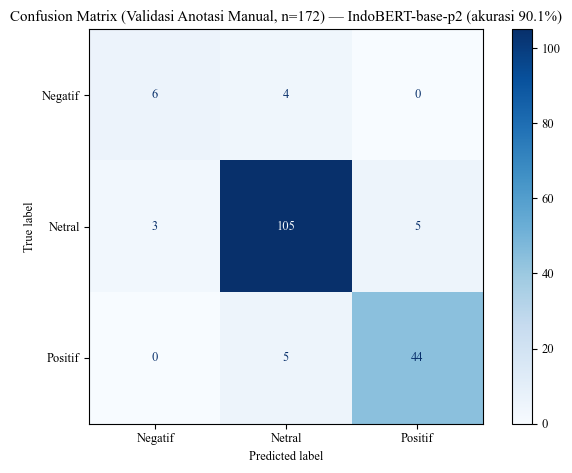

Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\confusion_matrix_validasi.png


In [71]:
# ════ SEL G : EVALUASI VALIDASI (data anotasi manual, ~20%) ════
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

# =========================
# PATH OUTPUT — pakai DIR_OUT & DIR_GAMBAR dari SEL A (tidak di-hardcode ulang)
# =========================
DIR_GAMBAR.mkdir(parents=True, exist_ok=True)


def prediksi_proba(texts, batch=64):
    model.eval()
    out = []

    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tokenizer(
                list(texts[i:i+batch]),
                truncation=True,
                padding=True,
                max_length=MAX_LEN,
                return_tensors='pt'
            ).to(DEVICE)

            logits = model(**enc).logits
            probs = torch.softmax(logits, dim=1)
            out.append(probs.cpu().numpy())

    return np.vstack(out)


proba_va = prediksi_proba(va['Teks'].tolist())
pred_va = proba_va.argmax(axis=1)
y_true = va['label_id'].values

acc = accuracy_score(y_true, pred_va)

print(f'AKURASI VALIDASI: {acc:.4f} ({acc*100:.1f}%)\n')

print(
    classification_report(
        y_true,
        pred_va,
        target_names=['Negatif', 'Netral', 'Positif']
    )
)

cm = confusion_matrix(y_true, pred_va)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negatif', 'Netral', 'Positif']
).plot(cmap='Blues')

plt.title(
    f'Confusion Matrix (Validasi Anotasi Manual, n={len(y_true)}) — '
    f'IndoBERT-base-p2 (akurasi {acc*100:.1f}%)'
)
plt.tight_layout()

PATH_CM = DIR_GAMBAR / 'confusion_matrix_validasi.png'
plt.savefig(PATH_CM, dpi=150, bbox_inches='tight')
plt.show()

print("Saved:", PATH_CM)

In [72]:
# ── Interval kepercayaan 95% (bootstrap) untuk akurasi & Macro F1 ──
from sklearn.metrics import accuracy_score, f1_score
rng = np.random.default_rng(42); n = len(y_true); acc_b, f1_b = [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    acc_b.append(accuracy_score(y_true[idx], pred_va[idx]))
    f1_b.append(f1_score(y_true[idx], pred_va[idx], labels=[0, 1, 2], average='macro', zero_division=0))
print(f"Akurasi : {acc:.3f}  (95% CI {np.percentile(acc_b,2.5):.3f}–{np.percentile(acc_b,97.5):.3f})")
print(f"Macro F1: {f1_score(y_true, pred_va, average='macro'):.3f}  "
      f"(95% CI {np.percentile(f1_b,2.5):.3f}–{np.percentile(f1_b,97.5):.3f})")

Akurasi : 0.901  (95% CI 0.855–0.942)
Macro F1: 0.818  (95% CI 0.702–0.906)


## 🎯 SEL H — Prediksi Skor Sentimen SEMUA Artikel (X2)

In [73]:
# ════ SEL H : PREDIKSI X2 SEMUA ARTIKEL ════
proba_all=prediksi_proba(df_berita['Teks'].tolist())
p_neg,p_net,p_pos=proba_all[:,0],proba_all[:,1],proba_all[:,2]
df_hasil=df_berita.copy()
df_hasil['P_Negatif']=p_neg.round(4); df_hasil['P_Netral']=p_net.round(4); df_hasil['P_Positif']=p_pos.round(4)
df_hasil['Skor_Sentimen']=(p_pos-p_neg).round(4)              # X2 kontinu [-1,1]
df_hasil['Confidence']=proba_all.max(1).round(4)
df_hasil['Label_Sentimen']=pd.Series(proba_all.argmax(1)).map(ID2LABEL).values
df_hasil['Sentimen_Diskrit']=df_hasil['Label_Sentimen'].map({'Positif':1,'Netral':0,'Negatif':-1})
df_hasil.to_csv(DIR_OUT/'skor_sentimen_per_artikel.csv',index=False,encoding='utf-8-sig')
print('💾 skor_sentimen_per_artikel.csv'); print(df_hasil['Label_Sentimen'].value_counts().to_string())
print(f'Skor: mean={df_hasil["Skor_Sentimen"].mean():+.3f} std={df_hasil["Skor_Sentimen"].std():.3f}')

💾 skor_sentimen_per_artikel.csv
Label_Sentimen
Netral     5891
Positif    2785
Negatif     604
Skor: mean=+0.235 std=0.533


In [74]:
import pandas as pd
from pathlib import Path

# ============================================================
# 1) Muat hasil prediksi semua judul (SEL H)
# ============================================================
if 'df_hasil' not in globals():
    PATH_SKOR = DIR_OUT / 'skor_sentimen_per_artikel.csv'
    assert PATH_SKOR.exists(), f'File skor tidak ditemukan: {PATH_SKOR}'
    df_hasil = pd.read_csv(PATH_SKOR, encoding='utf-8-sig')

df_all = df_hasil.copy()

# SEL H menyimpan label model sebagai Label_Sentimen
if 'Prediksi' not in df_all.columns:
    df_all['Prediksi'] = df_all['Label_Sentimen']
df_all['Prediksi'] = df_all['Prediksi'].astype(str).str.strip().str.lower()
df_all['Headline'] = df_all['Headline'].astype(str).str.strip()

print('Total judul:', len(df_all))
print('Distribusi prediksi:\n', df_all['Prediksi'].value_counts(), '\n')

# ============================================================
# 2) Muat 859 judul yang sudah pernah dilabeli
# ============================================================
lama_candidates = [
    ROOT / "02_preprocessing" / "sentimen_indobert" / "output_sentimen" / "anotasi_sentimen_VALID_gabungan.csv",
    DIR_OUT / "anotasi_sentimen_VALID_gabungan.csv",
    ROOT / "02_preprocessing" / "sentimen_indobert" / "output_sentimen 1" / "anotasi_sentimen_VALID_gabungan.csv",
]

PATH_LAMA = next((p for p in lama_candidates if p.exists()), None)
if PATH_LAMA is None:
    raise FileNotFoundError("File anotasi lama tidak ditemukan. Cek path berikut:\n" +
                            "\n".join(str(p) for p in lama_candidates))

lama = pd.read_csv(PATH_LAMA, encoding="utf-8-sig")
print('Anotasi lama dimuat dari:', PATH_LAMA, '| jumlah:', len(lama))

if "Headline" not in lama.columns:
    raise ValueError(f"Kolom 'Headline' tidak ada. Kolom tersedia: {lama.columns.tolist()}")

# ============================================================
# 3) Pengaturan output
# ============================================================
OUT = PATH_LAMA.parent / "anotasi_tambahan.xlsx"   # folder yang sama dengan anotasi lama
OUT.parent.mkdir(parents=True, exist_ok=True)
N_TOTAL = 700
SEED    = 42

# ============================================================
# 4) Buang judul yang sudah pernah dilabeli (termasuk 172 set uji) dan duplikat
# ============================================================
norm  = lambda s: s.astype(str).str.lower().str.strip()
sudah = set(norm(lama['Headline']))
kand  = df_all[~norm(df_all['Headline']).isin(sudah)].copy()
kand  = kand.loc[~norm(kand['Headline']).duplicated()]
print('Kandidat judul baru:', len(kand))

# ============================================================
# 5) Sampling bertingkat (kelas negatif diperbanyak)
# ============================================================
kuota = {'negatif': int(N_TOTAL*0.35), 'positif': int(N_TOTAL*0.30)}
kuota['netral'] = N_TOTAL - sum(kuota.values())

bagian = []
for k, n in kuota.items():
    pool = kand[kand['Prediksi'] == k]
    if len(pool) < n:
        print(f'⚠ Kelas {k}: hanya {len(pool)} tersedia (kuota {n})')
    bagian.append(pool.sample(n=min(n, len(pool)), random_state=SEED))

sampel = pd.concat(bagian).sample(frac=1, random_state=SEED).reset_index(drop=True)

# ============================================================
# 6) Simpan TANPA kolom prediksi agar anotasi tidak terpengaruh model
# ============================================================
sampel.insert(0, 'ID', range(1, len(sampel)+1))
sampel['Label_Manual'] = ''

kolom = [c for c in ['ID','Kode_Emiten','Tanggal','Headline','Label_Manual'] if c in sampel.columns]
sampel[kolom].to_excel(OUT, index=False)

print('\n✅', len(sampel), 'judul disimpan ke', OUT)
print('Kolom disimpan:', kolom)
print('\nSebaran per kelas prediksi (hanya untuk cek, tidak ikut disimpan):')
print(sampel['Prediksi'].value_counts())
if 'Kode_Emiten' in sampel.columns:
    print('\nSebaran per emiten:')
    print(sampel['Kode_Emiten'].value_counts())

Total judul: 9280
Distribusi prediksi:
 Prediksi
netral     5891
positif    2785
negatif     604
Name: count, dtype: int64 

Anotasi lama dimuat dari: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan.csv | jumlah: 859
Kandidat judul baru: 8387

✅ 700 judul disimpan ke E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_tambahan.xlsx
Kolom disimpan: ['ID', 'Kode_Emiten', 'Tanggal', 'Headline', 'Label_Manual']

Sebaran per kelas prediksi (hanya untuk cek, tidak ikut disimpan):
Prediksi
netral     246
negatif    244
positif    210
Name: count, dtype: int64

Sebaran per emiten:
Kode_Emiten
ADRO    169
PTBA    128
PGAS    111
MEDC    103
ITMG     74
AKRA     69
ADMR     46
Name: count, dtype: int64


## 🧩 SEL I — Confusion Matrix SELURUH Artikel (N=4.150) → Gambar 4.x

Membandingkan **prediksi IndoBERT** (`Label_Sentimen`) terhadap **Auto-Label leksikon** (`Label_Auto`) pada seluruh korpus.

> ⚠️ **Catatan metodologis (penting untuk Bab 3/4):** karena seluruh 4.150 artikel tidak memiliki label manual (ground truth), matriks ini berperan sebagai **matriks kesesuaian (agreement matrix)** antara dua metode pelabelan — bukan pengukuran akurasi absolut. Evaluasi akurasi resmi model tetap mengacu pada SEL G (validasi anotasi manual). Statistik pendukung: persentase kesesuaian dan **Cohen's Kappa**.

Total artikel        : 9,280
Kesesuaian (agreement): 0.8823 (88.2%)
Cohen's Kappa        : 0.7688

Classification report (referensi = Auto-Label leksikon — bersifat indikatif, bukan ground truth):
              precision    recall  f1-score   support

     Negatif       0.86      0.59      0.70       883
      Netral       0.91      0.91      0.91      5914
     Positif       0.82      0.92      0.87      2483

    accuracy                           0.88      9280
   macro avg       0.86      0.81      0.83      9280
weighted avg       0.88      0.88      0.88      9280



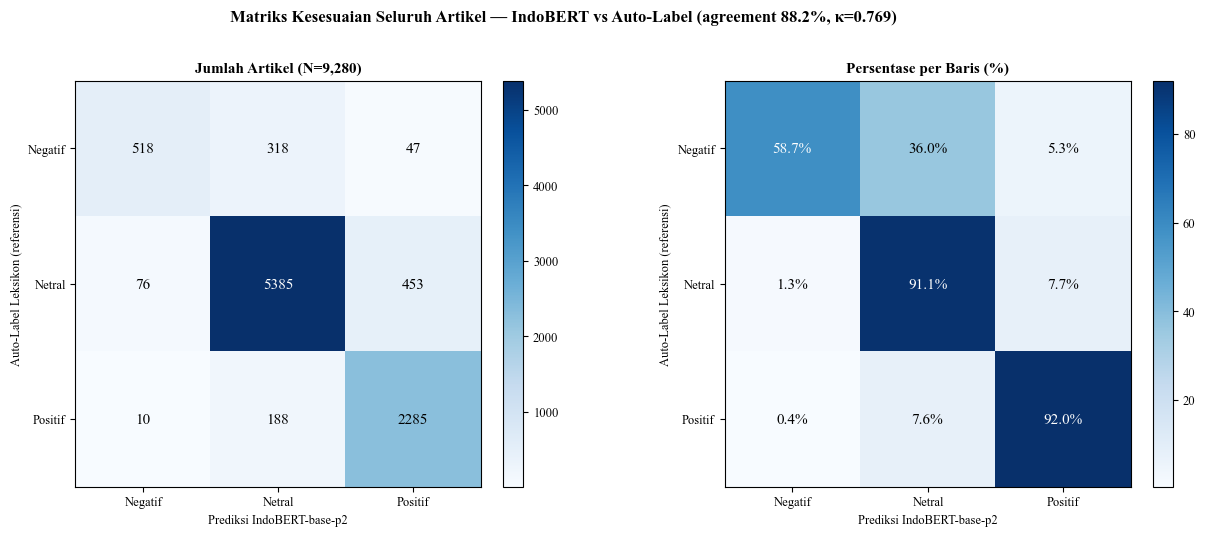

Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\confusion_matrix_seluruh_artikel.png
Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\tabel_confusion_matrix_seluruh_artikel.csv


In [75]:
# ════ SEL I : CONFUSION MATRIX SELURUH ARTIKEL (IndoBERT vs Auto-Label) ════
from sklearn.metrics import confusion_matrix, cohen_kappa_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

LABELS = ['Negatif', 'Netral', 'Positif']

# ── Pastikan kolom tersedia (Label_Auto dibuat di SEL C, terbawa ke df_hasil) ──
if 'Label_Auto' not in df_hasil.columns:
    print('Kolom Label_Auto belum ada di df_hasil — menghitung ulang dari SEL C...')
    df_hasil['Label_Auto'] = df_hasil['Teks'].apply(auto_label)

y_ref  = df_hasil['Label_Auto'].values        # referensi: leksikon (SEL C)
y_pred = df_hasil['Label_Sentimen'].values    # prediksi : IndoBERT fine-tuned (SEL H)
N = len(df_hasil)

# ── Statistik kesesuaian ──
agree = (y_ref == y_pred).mean()
kappa = cohen_kappa_score(y_ref, y_pred, labels=LABELS)
print(f'Total artikel        : {N:,}')
print(f'Kesesuaian (agreement): {agree:.4f} ({agree*100:.1f}%)')
print(f"Cohen's Kappa        : {kappa:.4f}")
print()
print('Classification report (referensi = Auto-Label leksikon — bersifat indikatif, bukan ground truth):')
print(classification_report(y_ref, y_pred, labels=LABELS, zero_division=0))

# ── Confusion matrix: hitungan absolut & normalisasi per-baris ──
cm_abs  = confusion_matrix(y_ref, y_pred, labels=LABELS)
cm_norm = cm_abs / cm_abs.sum(axis=1, keepdims=True) * 100  # % per baris referensi

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for ax, mat, judul, fmt in [
    (axes[0], cm_abs,  f'Jumlah Artikel (N={N:,})', 'd'),
    (axes[1], cm_norm, 'Persentase per Baris (%)',  '.1f'),
]:
    im = ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    ax.set_xlabel('Prediksi IndoBERT-base-p2')
    ax.set_ylabel('Auto-Label Leksikon (referensi)')
    ax.set_title(judul, fontweight='bold', fontsize=11)
    thresh = mat.max() / 2
    for r in range(3):
        for c in range(3):
            val = mat[r, c]
            teks = f'{val:{fmt}}' + ('%' if fmt != 'd' else '')
            ax.text(c, r, teks, ha='center', va='center',
                    color='white' if val > thresh else 'black', fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(
    f'Matriks Kesesuaian Seluruh Artikel — IndoBERT vs Auto-Label '
    f'(agreement {agree*100:.1f}%, κ={kappa:.3f})',
    fontweight='bold', fontsize=12, y=1.02
)
plt.tight_layout()

PATH_CM_ALL = DIR_GAMBAR / 'confusion_matrix_seluruh_artikel.png'
plt.savefig(PATH_CM_ALL, dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', PATH_CM_ALL)

# ── Simpan tabel CSV untuk lampiran Bab 4 ──
import pandas as pd
df_cm = pd.DataFrame(cm_abs, index=[f'Ref_{l}' for l in LABELS],
                     columns=[f'Pred_{l}' for l in LABELS])
df_cm['Total_Ref'] = df_cm.sum(axis=1)
df_cm.to_csv(DIR_TABLE / 'tabel_confusion_matrix_seluruh_artikel.csv', encoding='utf-8-sig')
print('Saved:', DIR_TABLE / 'tabel_confusion_matrix_seluruh_artikel.csv')


## 📊 SEL J — Distribusi Sentimen per Emiten → Tabel 4.x

Label_Sentimen  Positif  Netral  Negatif  Total  % Positif  % Netral  % Negatif
Kode_Emiten                                                                    
ADRO                698     977      162   1837       38.0      53.2        8.8
ADMR                143     176       46    365       39.2      48.2       12.6
ITMG                289     273       89    651       44.4      41.9       13.7
PTBA                506    1290       92   1888       26.8      68.3        4.9
MEDC                433     880       85   1398       31.0      62.9        6.1
AKRA                321     453       56    830       38.7      54.6        6.7
PGAS                395    1842       74   2311       17.1      79.7        3.2


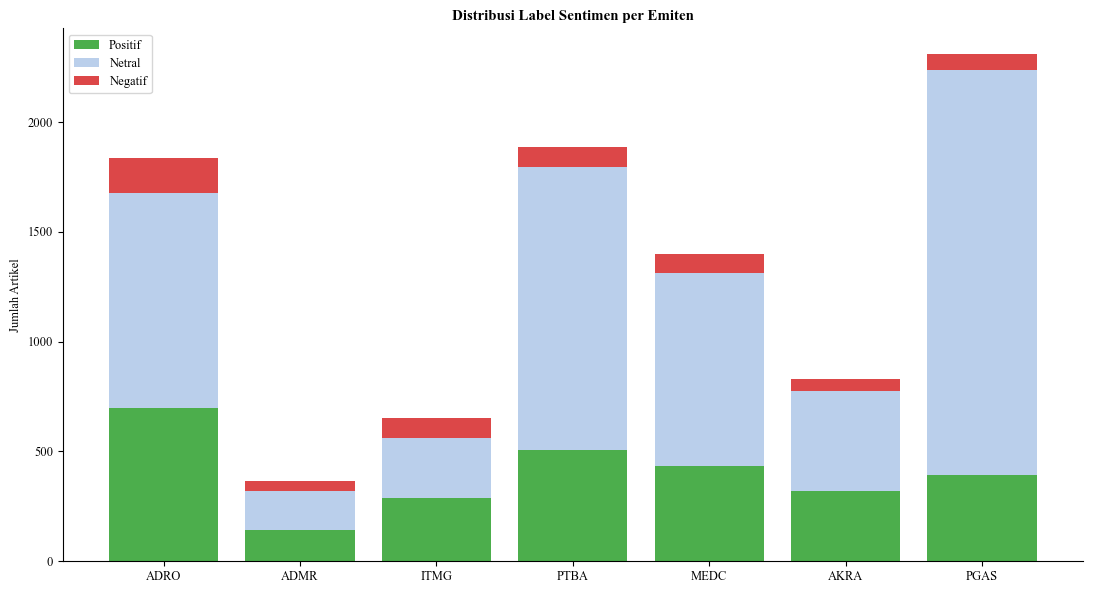

In [76]:
# ════ SEL J : DISTRIBUSI PER EMITEN ════

# cek kolom wajib
kolom_wajib = ['Kode_Emiten', 'Label_Sentimen', 'Headline']
missing = [c for c in kolom_wajib if c not in df_hasil.columns]
if missing:
    raise ValueError(f'Kolom tidak ditemukan: {missing}')

# pivot distribusi
pivot_dist = pd.pivot_table(
    df_hasil,
    index='Kode_Emiten',
    columns='Label_Sentimen',
    values='Headline',
    aggfunc='count',
    fill_value=0
).reindex(URUTAN_EMITEN, fill_value=0)

# pastikan semua label ada
for col in ['Positif', 'Netral', 'Negatif']:
    if col not in pivot_dist.columns:
        pivot_dist[col] = 0

pivot_dist = pivot_dist[['Positif', 'Netral', 'Negatif']]
pivot_dist['Total'] = pivot_dist.sum(axis=1)

# hindari division by zero
for c in ['Positif', 'Netral', 'Negatif']:
    pivot_dist[f'% {c}'] = np.where(
        pivot_dist['Total'] > 0,
        (pivot_dist[c] / pivot_dist['Total'] * 100).round(1),
        0
    )

print(pivot_dist.to_string())

# SAVE CSV
pivot_dist.to_csv(
    DIR_TABLE / 'tabel_distribusi_sentimen_per_emiten.csv',
    encoding='utf-8-sig'
)

# =========================
# PLOT
# =========================
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(pivot_dist))

ax.bar(x, pivot_dist['Positif'],
       label='Positif', color='#2ca02c', alpha=0.85)

ax.bar(x, pivot_dist['Netral'],
       bottom=pivot_dist['Positif'],
       label='Netral', color='#aec7e8', alpha=0.85)

ax.bar(x, pivot_dist['Negatif'],
       bottom=pivot_dist['Positif'] + pivot_dist['Netral'],
       label='Negatif', color='#d62728', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(pivot_dist.index)
ax.set_ylabel('Jumlah Artikel')
ax.set_title('Distribusi Label Sentimen per Emiten', fontweight='bold')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(
    DIR_IMG / 'distribusi_sentimen_per_emiten.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

## 📅 SEL K — Agregasi Skor Sentimen Harian (+ forward-fill)

In [77]:
# ════ SEL K : AGREGASI HARIAN (REVISI REVIEWER — pemetaan ke hari bursa) ════
df_hasil['Tanggal']=pd.to_datetime(df_hasil['Tanggal'],errors='coerce')
df_hasil['Tanggal']=df_hasil['Tanggal'].dt.tz_localize(None).dt.normalize()   # buang jam/zona waktu

# ── FIX AUDIT #1: pakai kalender hari bursa ASLI dari technical_features.csv
# (PREP_01) kalau tersedia — supaya tanggal 100% sinkron saat merge X1+X2.
# Fallback ke bdate_range generik kalau file belum ada (mis. urutan eksekusi
# PREP_02 sebelum PREP_01).
PATH_TEKNIKAL = DIR_PROCESSED / 'technical_features.csv'
if PATH_TEKNIKAL.exists():
    _tgl_teknikal = pd.read_csv(PATH_TEKNIKAL, usecols=['Date'])['Date']
    hari = pd.to_datetime(sorted(_tgl_teknikal.unique()))
    print(f'  ℹ️  Kalender hari bursa dipakai dari technical_features.csv '
          f'({len(hari)} hari, {hari.min().date()} → {hari.max().date()})')
else:
    hari = pd.bdate_range(df_hasil['Tanggal'].min(), df_hasil['Tanggal'].max())
    print(f'  ⚠️  technical_features.csv belum ada — fallback ke bdate_range '
          f'generik ({len(hari)} hari). Jalankan ulang SEL K setelah PREP_01 '
          f'selesai supaya kalender 100% sinkron.')


# ── REVISI REVIEWER (Komentar #5): berita yang terbit pada hari NON-BURSA
# (Sabtu/Minggu/libur) dipetakan ke HARI BURSA BERIKUTNYA, sesuai metodologi
# di naskah. Versi lama: berita tsb terbuang diam-diam saat merge ke kalender.
_n_awal = len(df_hasil)
_tgl_asli = df_hasil['Tanggal'].copy()
_pos = hari.searchsorted(df_hasil['Tanggal'].values, side='left')
_valid = (_pos < len(hari)) & df_hasil['Tanggal'].notna().values
df_hasil = df_hasil.loc[_valid].copy()
df_hasil['Tanggal'] = hari[_pos[_valid]]
_n_geser = int((df_hasil['Tanggal'] != _tgl_asli.loc[df_hasil.index]).sum())
print(f'  📅 Artikel total            : {_n_awal:,}')
print(f'  📅 Digeser ke hari bursa +1 : {_n_geser:,} (terbit di hari non-bursa)')
print(f'  📅 Dibuang (di luar periode): {_n_awal - len(df_hasil):,}')

df_agg=(df_hasil.groupby(['Kode_Emiten','Tanggal'])
    .agg(Skor_Sentimen=('Skor_Sentimen','mean'),
         Skor_Sentimen_Std=('Skor_Sentimen','std'),
         Confidence_Mean=('Confidence','mean'),
         Jumlah_Artikel=('Skor_Sentimen','count'),
         N_Positif=('Label_Sentimen',lambda x:(x=='Positif').sum()),
         N_Negatif=('Label_Sentimen',lambda x:(x=='Negatif').sum()),
         N_Netral =('Label_Sentimen',lambda x:(x=='Netral').sum()))
    .reset_index())
df_agg['Skor_Sentimen_Std']=df_agg['Skor_Sentimen_Std'].fillna(0)
df_agg['Skor_Sentimen']=df_agg['Skor_Sentimen'].round(4); df_agg['Ada_Berita']=1

idx=pd.MultiIndex.from_product([URUTAN_EMITEN,hari],names=['Kode_Emiten','Tanggal'])
df_full=pd.DataFrame(index=idx).reset_index().merge(df_agg,on=['Kode_Emiten','Tanggal'],how='left')
df_full['Ada_Berita']=df_full['Ada_Berita'].fillna(0).astype(int)
df_full=df_full.sort_values(['Kode_Emiten','Tanggal'])
df_full['Skor_Sentimen']=df_full.groupby('Kode_Emiten')['Skor_Sentimen'].ffill().fillna(0.0)

# ── FIX AUDIT #2: Skor_Sentimen_Std (dispersi/ketidaksepakatan opini pasar)
# TETAP dipertahankan — forward-fill sejalan dengan Skor_Sentimen, bukan
# dibuang sebelum export seperti versi sebelumnya.
df_full['Skor_Sentimen_Std']=df_full.groupby('Kode_Emiten')['Skor_Sentimen_Std'].ffill().fillna(0.0)

for c in ['Jumlah_Artikel','N_Positif','N_Negatif','N_Netral']:
    df_full[c]=df_full[c].fillna(0).astype(int)
df_full['Skor_Sentimen_Mean']=df_full['Skor_Sentimen']
print('Total hari-emiten:',len(df_full)); print(df_full.head(8).to_string(index=False))

  ℹ️  Kalender hari bursa dipakai dari technical_features.csv (1074 hari, 2022-01-03 → 2026-06-30)
  📅 Artikel total            : 9,280
  📅 Digeser ke hari bursa +1 : 1,079 (terbit di hari non-bursa)
  📅 Dibuang (di luar periode): 0
Total hari-emiten: 7518
Kode_Emiten    Tanggal  Skor_Sentimen  Skor_Sentimen_Std  Confidence_Mean  Jumlah_Artikel  N_Positif  N_Negatif  N_Netral  Ada_Berita  Skor_Sentimen_Mean
       ADMR 2022-01-03         0.6127           0.537189          0.87430               2          1          0         1           1              0.6127
       ADMR 2022-01-04         0.4968           0.704066          0.99450               2          1          0         1           1              0.4968
       ADMR 2022-01-05         0.4968           0.704066              NaN               0          0          0         0           0              0.4968
       ADMR 2022-01-06         0.4968           0.704066              NaN               0          0          0         0      

## 📈 SEL L — Visualisasi Tren Sentimen Harian → Gambar 4.x

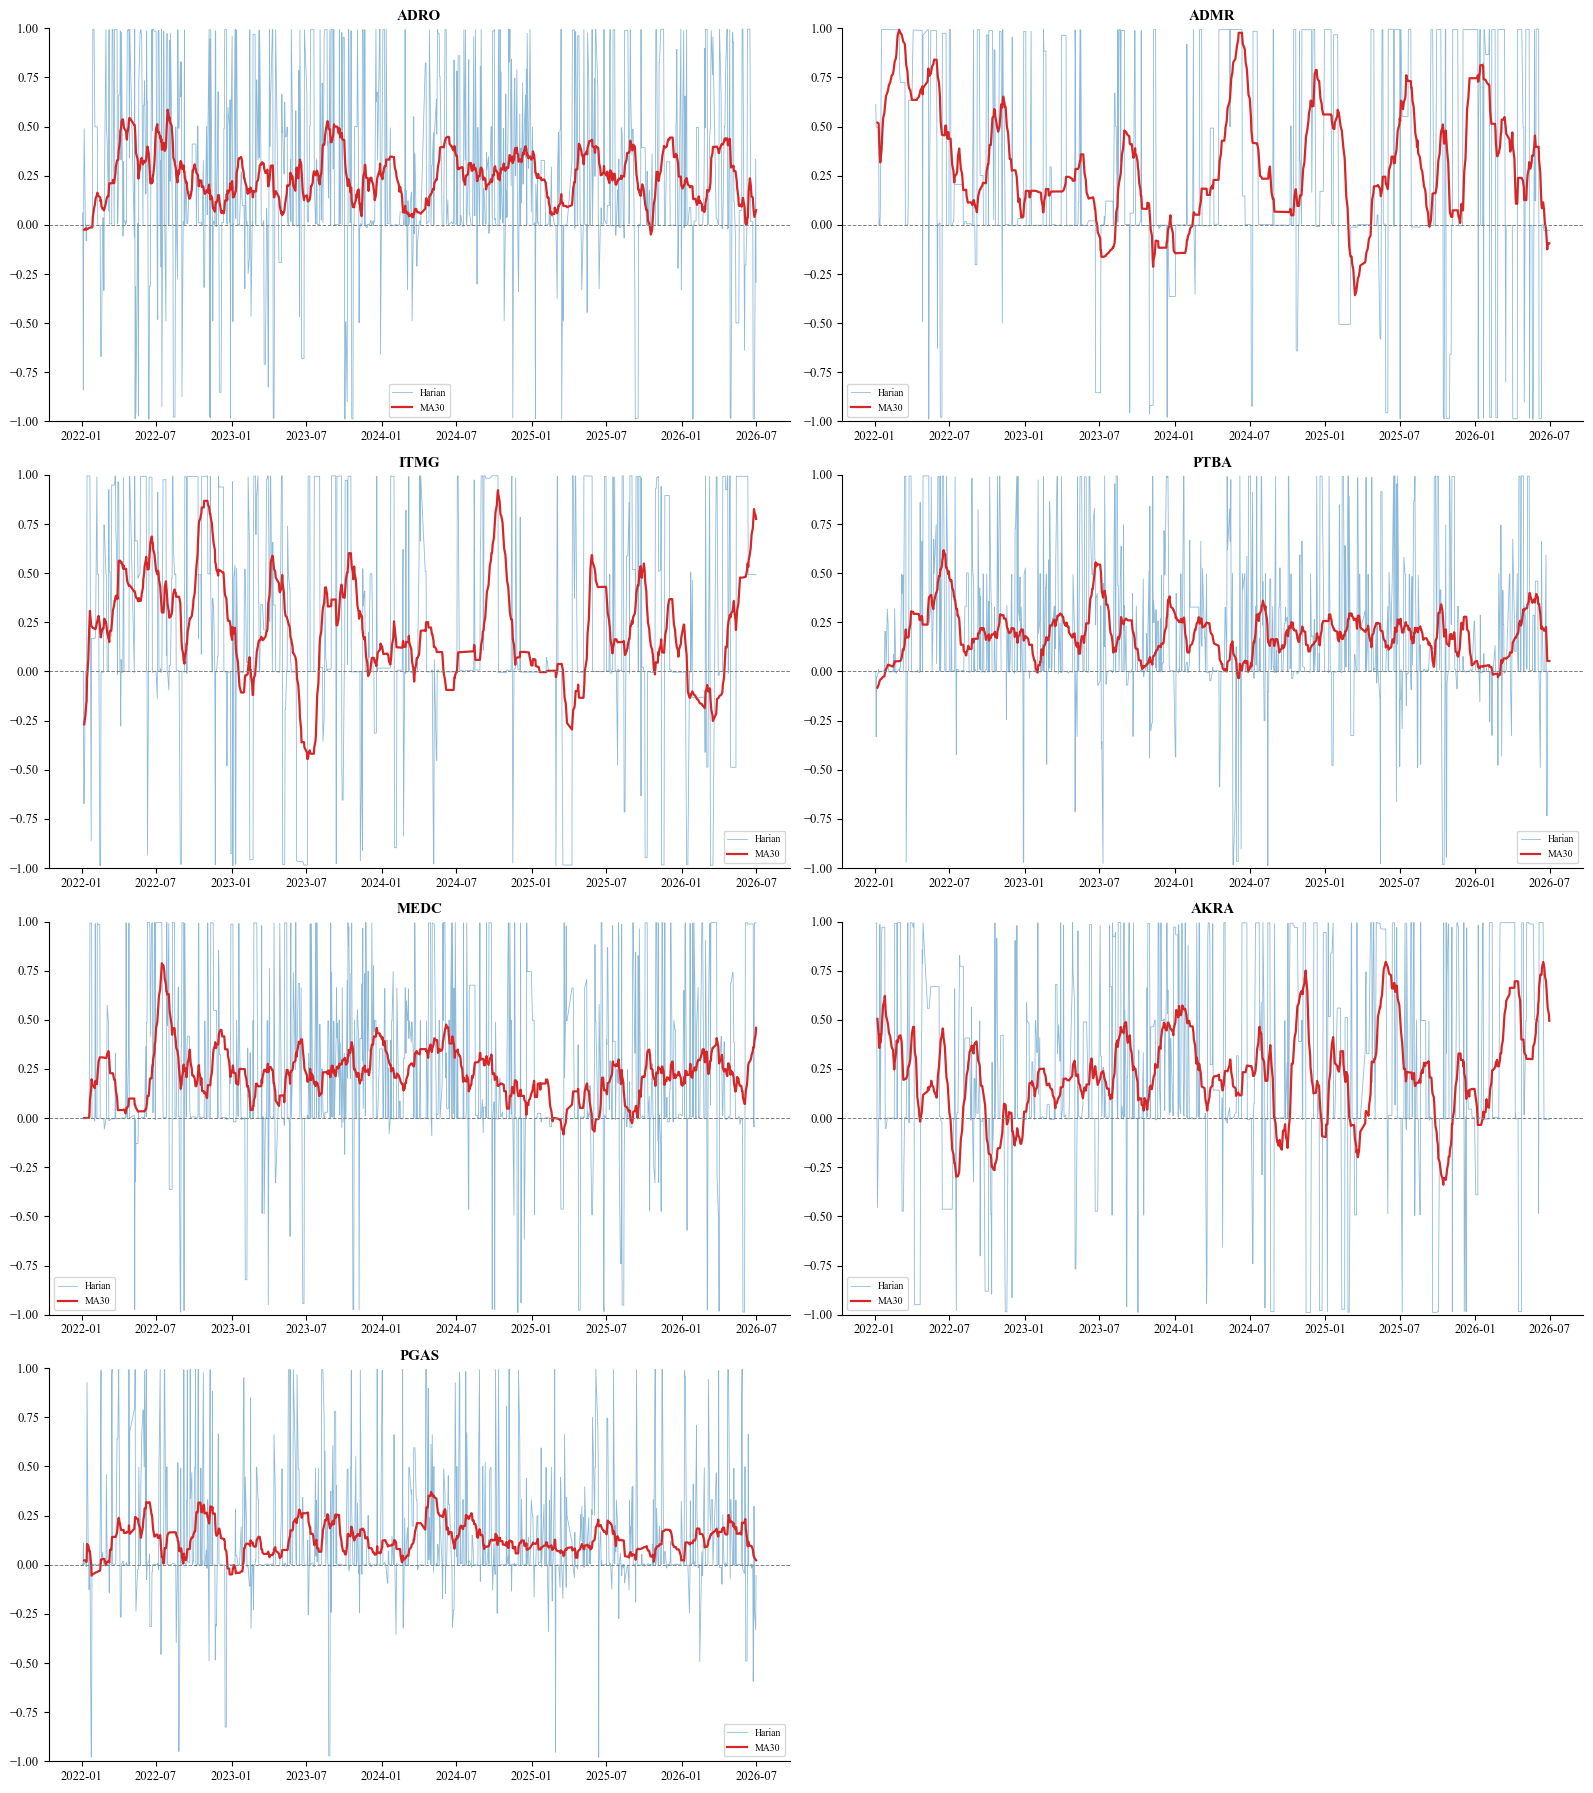

In [78]:
# ════ SEL L : TREN HARIAN ════
fig,axes=plt.subplots(4,2,figsize=(16,18)); axes=axes.flatten()
for i,em in enumerate(URUTAN_EMITEN):
    g=df_full[df_full['Kode_Emiten']==em].set_index('Tanggal')
    ax=axes[i]
    ax.plot(g.index,g['Skor_Sentimen'],lw=.6,color='#1f77b4',alpha=.5,label='Harian')
    ax.plot(g.index,g['Skor_Sentimen'].rolling(30,min_periods=5).mean(),lw=1.6,color='#d62728',label='MA30')
    ax.axhline(0,color='gray',ls='--',lw=.7); ax.set_title(em,fontweight='bold')
    ax.set_ylim(-1,1); ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
for j in range(len(URUTAN_EMITEN),len(axes)): axes[j].axis('off')
plt.tight_layout(); plt.savefig(DIR_GAMBAR/'tren_sentimen_harian.png',dpi=150,bbox_inches='tight'); plt.show()

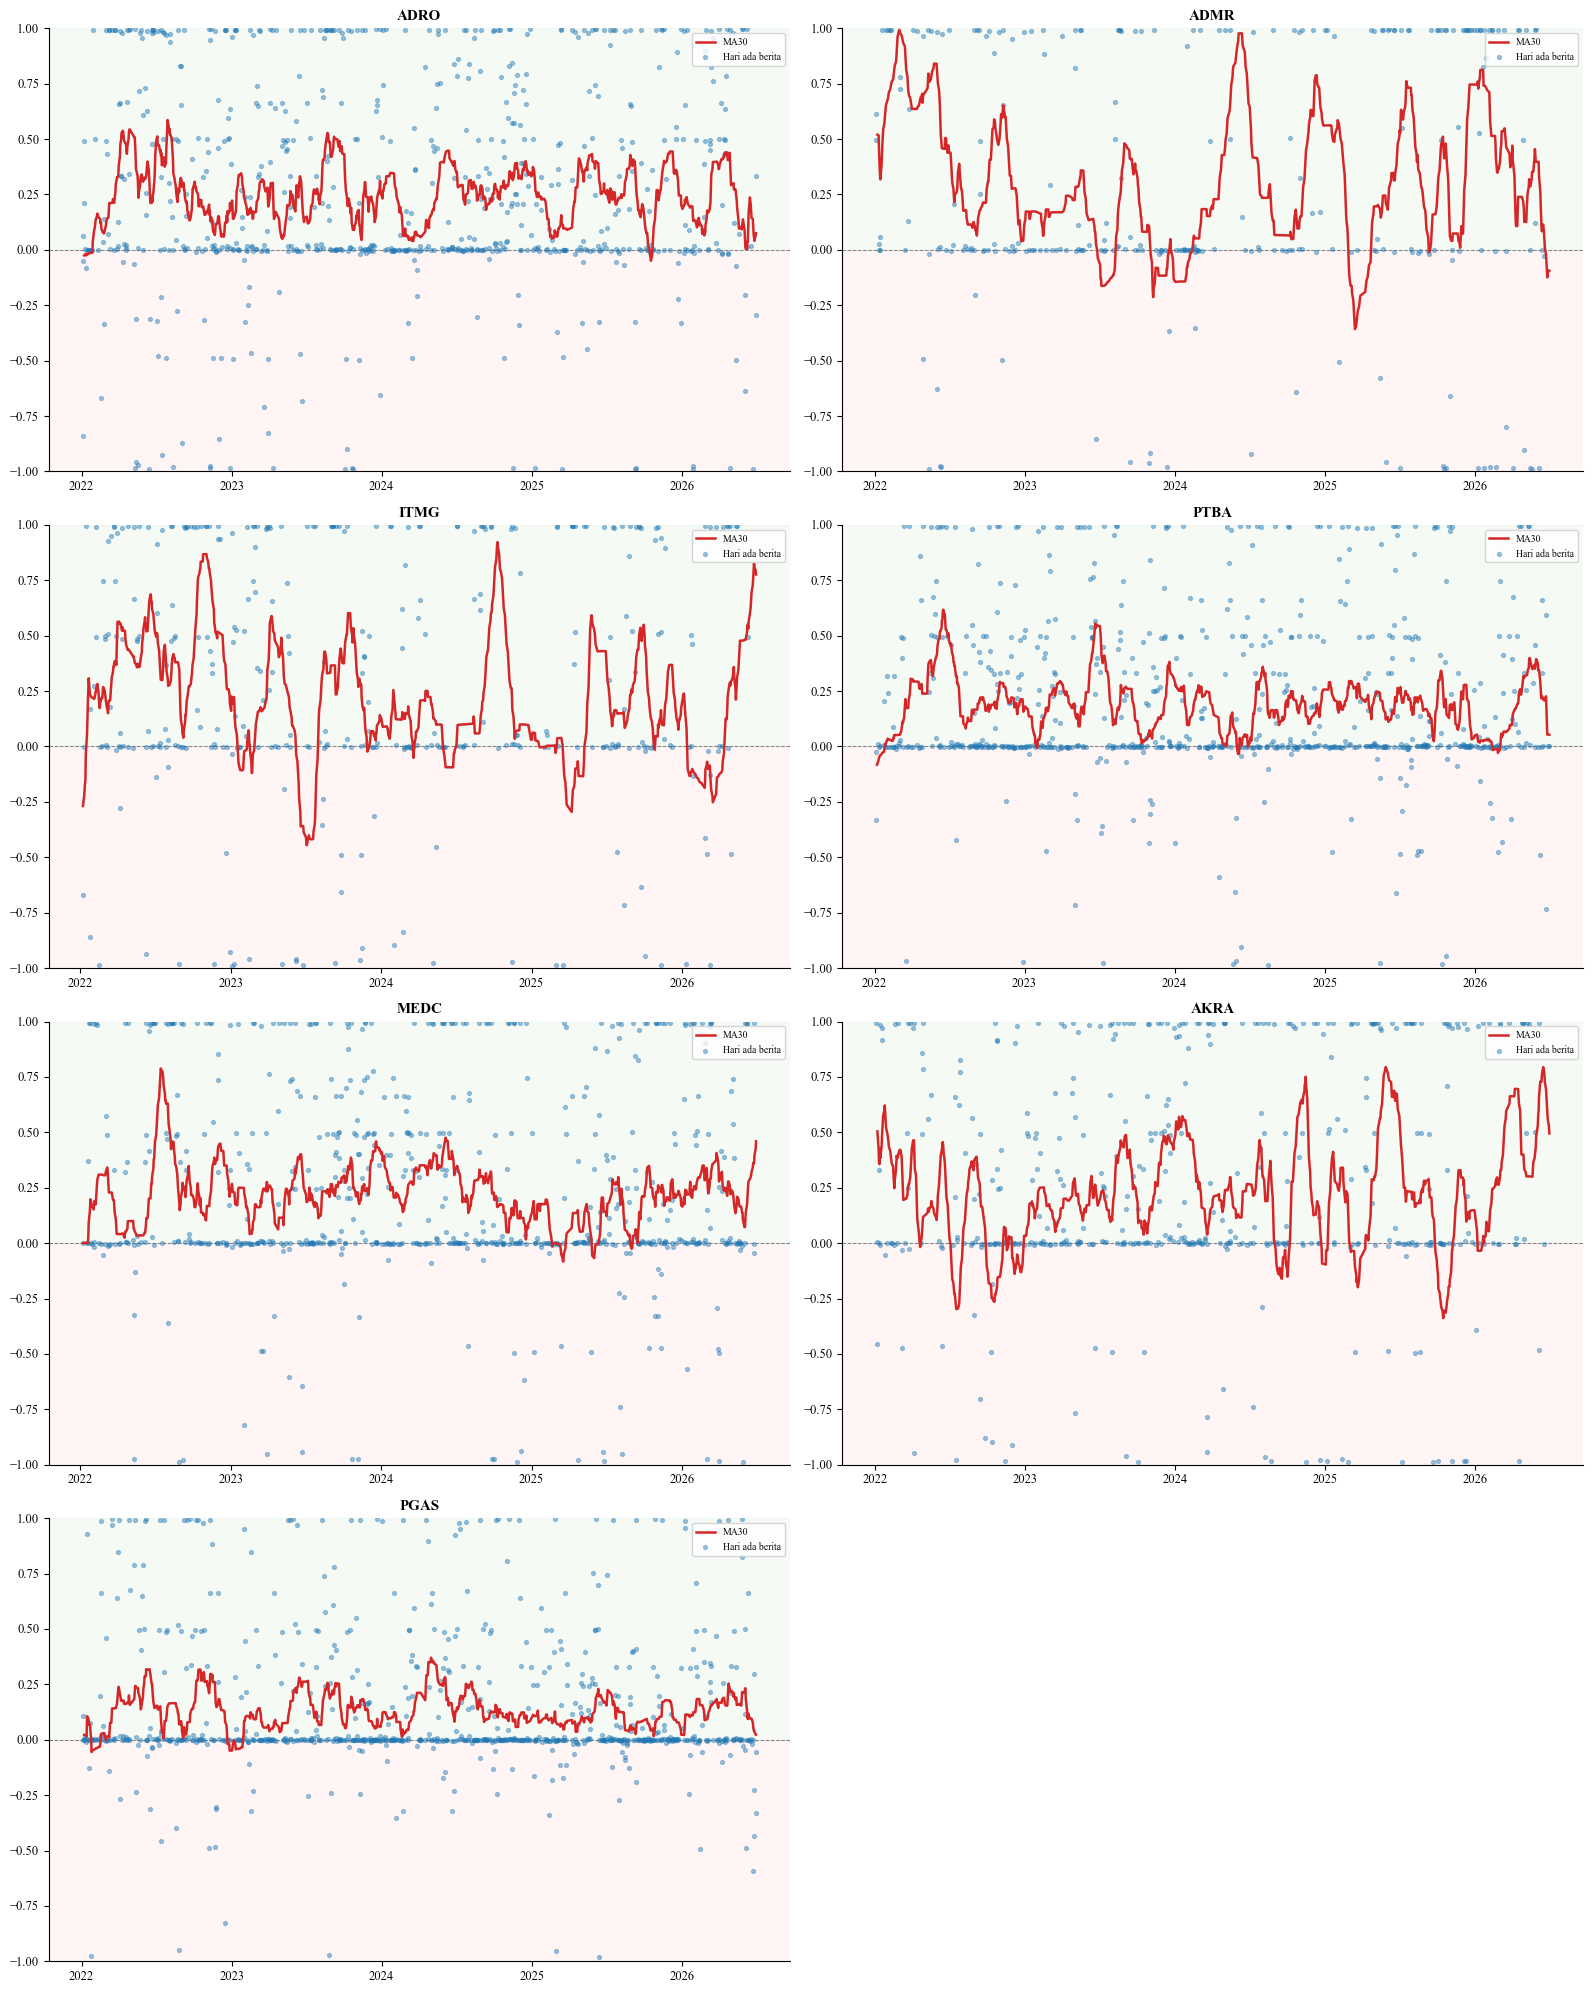

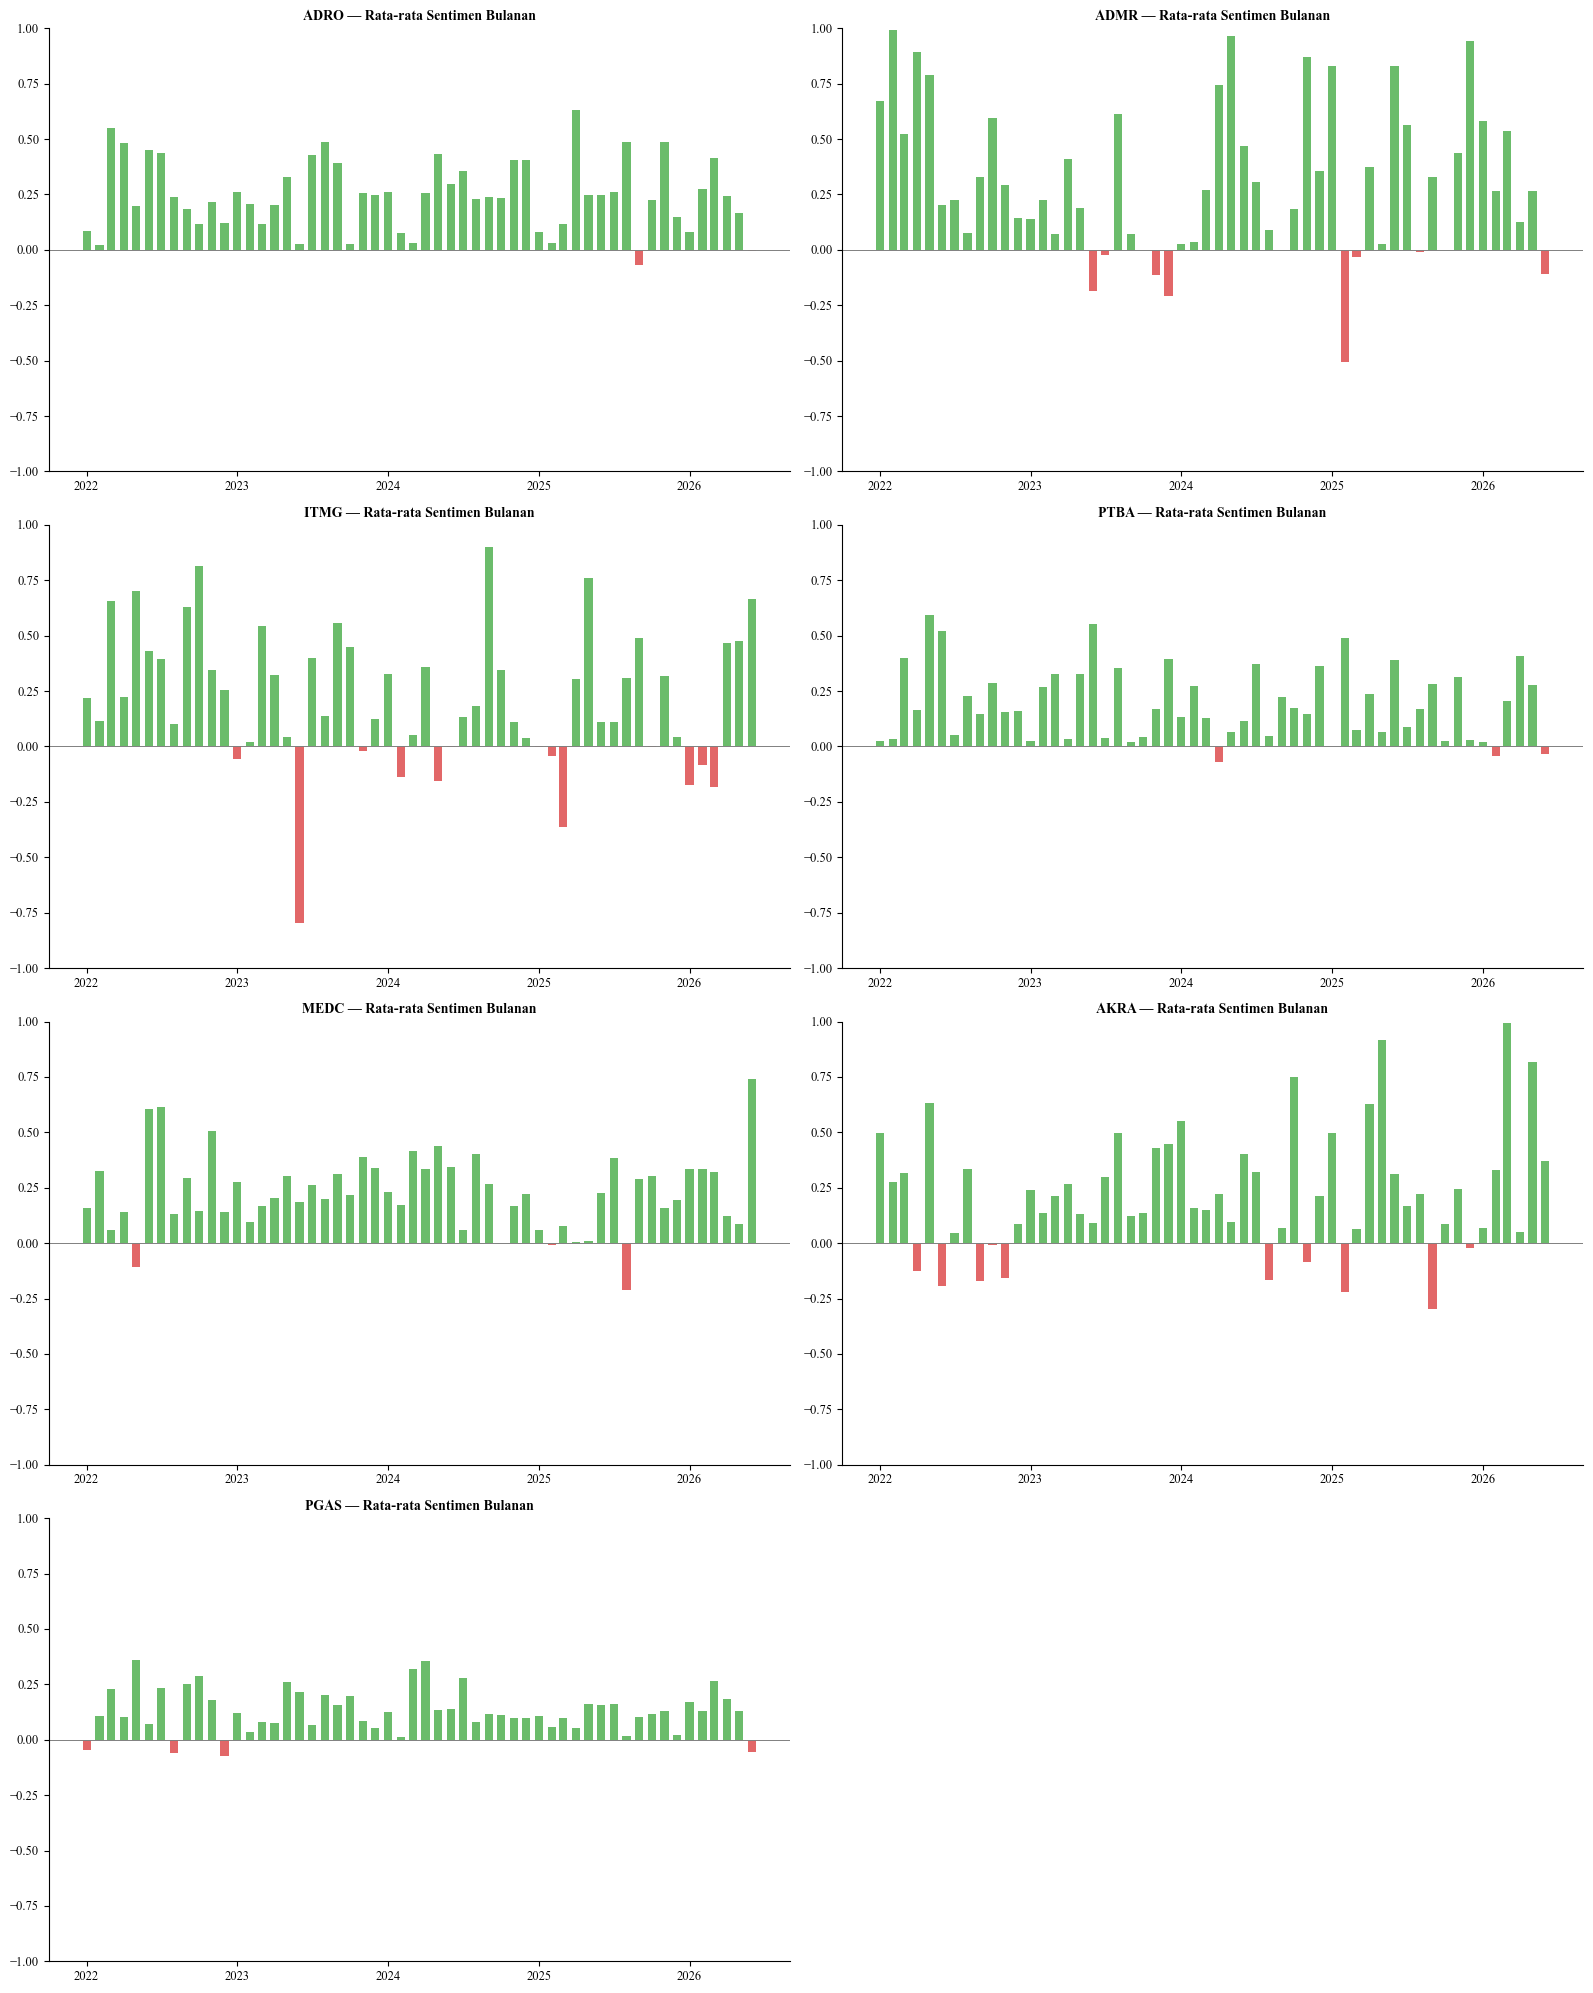

✅ Disimpan: tren_sentimen_harian_v2.png & tren_sentimen_bulanan.png


In [79]:
# ════ SEL L (VERSI DIPERBAIKI) — TREN SENTIMEN + VOLUME BERITA ════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(4, 2, figsize=(16, 20),
                          gridspec_kw={'height_ratios': [1]*4})
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].set_index('Tanggal')
    ax = axes[i]

    # ── Panel utama: MA30 + scatter hari yang benar-benar ada berita ──
    ax.plot(g.index, g['Skor_Sentimen'].rolling(30, min_periods=5).mean(),
            lw=1.8, color='#d62728', label='MA30', zorder=3)

    # Hanya scatter di hari yang benar-benar ada berita (bukan forward-fill)
    if 'Ada_Berita' in g.columns:
        hari_berita = g[g['Ada_Berita'] == 1]
    else:
        hari_berita = g  # fallback kalau kolom tidak tersedia

    ax.scatter(hari_berita.index, hari_berita['Skor_Sentimen'],
               s=8, color='#1f77b4', alpha=0.4, label='Hari ada berita', zorder=2)

    # Shading area positif/negatif
    ax.axhspan(0, 1, color='green', alpha=0.04)
    ax.axhspan(-1, 0, color='red', alpha=0.04)
    ax.axhline(0, color='gray', ls='--', lw=0.7, zorder=1)

    ax.set_title(em, fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.legend(fontsize=7, loc='upper right')
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_harian_v2.png', dpi=150, bbox_inches='tight')
plt.show()


# ════ TAMBAHAN: PANEL VOLUME BERITA PER BULAN (opsional, per emiten) ════
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].copy()
    g['Bulan'] = pd.to_datetime(g['Tanggal']).dt.to_period('M')

    # Agregasi bulanan: rata-rata sentimen & jumlah artikel
    agg = g.groupby('Bulan').agg(
        Sentimen=('Skor_Sentimen', 'mean'),
        Jumlah_Artikel=('Jumlah_Artikel', 'sum') if 'Jumlah_Artikel' in g.columns else ('Skor_Sentimen', 'count')
    ).reset_index()
    agg['Bulan'] = agg['Bulan'].dt.to_timestamp()

    ax = axes[i]
    colors = ['#2ca02c' if v >= 0 else '#d62728' for v in agg['Sentimen']]
    ax.bar(agg['Bulan'], agg['Sentimen'], width=20, color=colors, alpha=0.7)
    ax.axhline(0, color='gray', lw=0.7)
    ax.set_title(f'{em} — Rata-rata Sentimen Bulanan', fontweight='bold', fontsize=10)
    ax.set_ylim(-1, 1)
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_bulanan.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ Disimpan: tren_sentimen_harian_v2.png & tren_sentimen_bulanan.png')

In [80]:
# ════ FUNGSI TAMBAHAN — ZOOM TREN HARIAN KE 1 BULAN TERTENTU ════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

def plot_tren_bulanan(emiten, tahun, bulan, simpan=True):
    """
    Menampilkan tren sentimen harian untuk 1 emiten pada 1 bulan tertentu.

    Parameter:
        emiten : str  -> contoh 'ADRO'
        tahun  : int  -> contoh 2024
        bulan  : int  -> 1-12
        simpan : bool -> simpan gambar ke DIR_GAMBAR jika True
    """
    g = df_full[df_full['Kode_Emiten'] == emiten].copy()
    g['Tanggal'] = pd.to_datetime(g['Tanggal'])
    mask = (g['Tanggal'].dt.year == tahun) & (g['Tanggal'].dt.month == bulan)
    g_bulan = g[mask].sort_values('Tanggal')

    if g_bulan.empty:
        print(f'Tidak ada data untuk {emiten} pada {bulan}/{tahun}')
        return

    fig, ax = plt.subplots(figsize=(10, 4))

    # Garis forward-fill (abu-abu tipis)
    ax.plot(g_bulan['Tanggal'], g_bulan['Skor_Sentimen'],
            lw=1.2, color='#898781', alpha=0.6, zorder=1)

    # Titik hanya di hari yang benar-benar ada berita
    if 'Ada_Berita' in g_bulan.columns:
        hari_berita = g_bulan[g_bulan['Ada_Berita'] == 1]
    else:
        hari_berita = g_bulan

    ax.scatter(hari_berita['Tanggal'], hari_berita['Skor_Sentimen'],
               s=40, color='#2a78d6', zorder=2, label='Hari ada berita')

    ax.axhspan(0, 1, color='green', alpha=0.04)
    ax.axhspan(-1, 0, color='red', alpha=0.04)
    ax.axhline(0, color='gray', ls='--', lw=0.7)

    nama_bulan = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
    ax.set_title(f'{emiten} — Tren Sentimen Harian, {nama_bulan[bulan-1]} {tahun}',
                 fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.set_ylabel('Skor Sentimen')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
    ax.set_xlabel('Tanggal')
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    if simpan:
        fname = f'tren_{emiten}_{tahun}_{bulan:02d}.png'
        plt.savefig(DIR_GAMBAR / fname, dpi=150, bbox_inches='tight')
        print(f'✅ Disimpan: {fname}')
    plt.show()


# ── Contoh pemakaian ──
# plot_tren_bulanan('ADRO', 2025, 7)   # tren ADRO bulan Juli 2025
# plot_tren_bulanan('ITMG', 2024, 6)   # tren ITMG bulan Juni 2024

## 💾 SEL M — Simpan X2 Harian + Quality Check

In [81]:
# ════ SEL M : SIMPAN + QC (REVISI AUDIT) ════
# FIX AUDIT #1: kolom kunci di-rename ke 'Emiten'/'Date' supaya PERSIS SAMA
# dengan technical_features.csv (PREP_01) — merge X1+X2 tidak akan gagal
# diam-diam gara-gara nama kolom beda ('Kode_Emiten'/'Tanggal' vs 'Emiten'/'Date').
# FIX AUDIT #2: Sentiment_Dispersion (std sentimen antar berita per hari)
# ikut disimpan — sebelumnya dihitung di SEL K tapi dibuang di sini.
df_final = df_full[[
    'Kode_Emiten', 'Tanggal', 'Skor_Sentimen', 'Skor_Sentimen_Std',
    'Jumlah_Artikel', 'Ada_Berita'
]].copy()

df_final = df_final.rename(columns={
    'Kode_Emiten': 'Emiten',
    'Tanggal': 'Date',
    'Skor_Sentimen': 'Sentiment_Mean',
    'Skor_Sentimen_Std': 'Sentiment_Dispersion',
    'Jumlah_Artikel': 'News_Count',
})

df_final['Date'] = pd.to_datetime(df_final['Date'])
df_final = df_final.sort_values(['Emiten', 'Date']).reset_index(drop=True)

path_final = DIR_PROCESSED / 'skor_sentimen_harian.csv'
df_final.to_csv(path_final, index=False, encoding='utf-8-sig')
print(f'✅ {path_final}  ({len(df_final):,} baris)')
print(f'   Kolom: {df_final.columns.tolist()}')

print('\nStatistik per emiten:')
print(df_final.groupby('Emiten')[['Sentiment_Mean','Sentiment_Dispersion']]
      .agg(['mean','std','min','max']).round(4).reindex(URUTAN_EMITEN).to_string())
print('\nMissing:', df_final.isnull().sum().sum(), '| Duplikat:', df_final.duplicated().sum())
print('Range tgl:', df_final['Date'].min().date(), '->', df_final['Date'].max().date())

✅ E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv  (7,518 baris)
   Kolom: ['Emiten', 'Date', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']

Statistik per emiten:
       Sentiment_Mean                         Sentiment_Dispersion                     
                 mean     std     min     max                 mean     std  min     max
Emiten                                                                                 
ADRO           0.2476  0.4884 -0.9887  0.9959               0.2083  0.3138  0.0  1.3940
ADMR           0.3000  0.5673 -0.9884  0.9959               0.0587  0.1968  0.0  1.3821
ITMG           0.2264  0.5613 -0.9888  0.9959               0.1558  0.3404  0.0  1.3987
PTBA           0.1905  0.3948 -0.9882  0.9956               0.1784  0.2707  0.0  1.3434
MEDC           0.2326  0.4520 -0.9880  0.9959               0.1687  0.2776 

## 📦 SEL N — Export Final (siap merge dengan Y & X1)

In [82]:
# ════ SEL N : EXPORT READY FOR MERGE (REVISI AUDIT) ════
df_final.to_csv(DIR_PROCESSED/'sentiment_ready_for_merge.csv',index=False,encoding='utf-8-sig')
print('✅ sentiment_ready_for_merge.csv')
print(f'   Kolom kunci merge: Emiten, Date  (SAMA PERSIS dengan technical_features.csv)')
print(f'   Kolom fitur X2   : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita')
print()
print('📌 Contoh merge di notebook integrasi (05_integrasi_dataset.ipynb):')
print('   df_master = df_x1.merge(df_x2, on=[\'Date\', \'Emiten\'], how=\'inner\')')

✅ sentiment_ready_for_merge.csv
   Kolom kunci merge: Emiten, Date  (SAMA PERSIS dengan technical_features.csv)
   Kolom fitur X2   : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita

📌 Contoh merge di notebook integrasi (05_integrasi_dataset.ipynb):
   df_master = df_x1.merge(df_x2, on=['Date', 'Emiten'], how='inner')


In [83]:
  t = pd.to_datetime(df_berita['Tanggal'], errors='coerce')
  print('Artikel yang punya jam (bukan 00:00):', f"{(t.dt.time != pd.Timestamp('00:00').time()).mean():.1%}")
  print(t.dt.hour.value_counts().sort_index().to_string())

Artikel yang punya jam (bukan 00:00): 0.0%
Tanggal
0    9280


In [84]:
import pandas as pd

df = df_berita.copy()   # ganti jika nama DataFrame berita berbeda
print('Kolom tersedia:', list(df.columns), '\n')

def cari_kolom(kandidat):
    for c in df.columns:
        if c.lower() in kandidat:
            return c
    return None

k_judul  = cari_kolom({'judul', 'title', 'headline', 'judul_berita', 'text', 'teks', 'berita'})
k_tgl    = cari_kolom({'tanggal', 'date', 'tgl', 'published', 'tanggal_terbit', 'publish_date'})
k_emiten = cari_kolom({'emiten', 'ticker', 'kode', 'kode_emiten', 'saham', 'stock', 'symbol'})
k_sumber = cari_kolom({'sumber', 'source', 'portal', 'media', 'situs'})
print(f'Terdeteksi -> judul: {k_judul} | tanggal: {k_tgl} | emiten: {k_emiten} | sumber: {k_sumber}\n')

print('Total baris           :', len(df))
if k_judul:
    print('Judul unik            :', df[k_judul].nunique())
kunci = [k for k in (k_judul, k_tgl, k_emiten) if k]
if kunci:
    print(f'Duplikat ({", ".join(kunci)}):', df.duplicated(subset=kunci).sum())
if k_judul and k_emiten:
    print('Judul yang muncul di >1 emiten:',
          (df.groupby(k_judul)[k_emiten].nunique() > 1).sum())
if k_emiten:
    print('\nPer emiten:'); print(df[k_emiten].value_counts())
if k_sumber:
    print('\nPer sumber:'); print(df[k_sumber].value_counts())

Kolom tersedia: ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita', 'Teks', 'Label_Auto'] 

Terdeteksi -> judul: Headline | tanggal: Tanggal | emiten: Kode_Emiten | sumber: Sumber

Total baris           : 9280
Judul unik            : 9255
Duplikat (Headline, Tanggal, Kode_Emiten): 9
Judul yang muncul di >1 emiten: 1

Per emiten:
Kode_Emiten
PGAS    2311
PTBA    1888
ADRO    1837
MEDC    1398
AKRA     830
ITMG     651
ADMR     365
Name: count, dtype: int64

Per sumber:
Sumber
Kontan           5405
Antara           1715
Detik Finance    1074
CNBC              967
Bloomberg         119
Name: count, dtype: int64


In [85]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix
import pandas as pd

labels = lab[['Label_Auto', 'Label_Manual']].dropna()
n = len(labels)
berubah = (labels['Label_Auto'] != labels['Label_Manual']).sum()
kappa = cohen_kappa_score(labels['Label_Auto'], labels['Label_Manual'])

print(f'Jumlah judul diverifikasi : {n}')
print(f'Label dikoreksi manual    : {berubah} ({berubah / n:.1%})')
print(f"Cohen's kappa (Auto vs Manual): {kappa:.3f}")

urutan = sorted(labels['Label_Manual'].unique())
print('\nMatriks (baris = Auto, kolom = Manual):')
print(pd.DataFrame(confusion_matrix(labels['Label_Auto'], labels['Label_Manual'], labels=urutan),
                   index=[f'Auto {u}' for u in urutan], columns=[f'Manual {u}' for u in urutan]))
print('\nDistribusi label manual:')
print(labels['Label_Manual'].value_counts())

Jumlah judul diverifikasi : 859
Label dikoreksi manual    : 0 (0.0%)
Cohen's kappa (Auto vs Manual): 1.000

Matriks (baris = Auto, kolom = Manual):
              Manual Negatif  Manual Netral  Manual Positif
Auto Negatif              51              0               0
Auto Netral                0            565               0
Auto Positif               0              0             243

Distribusi label manual:
Label_Manual
Netral     565
Positif    243
Negatif     51
Name: count, dtype: int64


In [86]:
# ════ EVALUASI INDOBERT TERHADAP LABEL ANOTASI ════
import pandas as pd
from pathlib import Path
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, classification_report

LABEL_VALID = ['Positif', 'Netral', 'Negatif']

# ── 1. Lokasi file: simpan file yang dikirim (anotasi_manual_LabelB_LLM.xlsx) ke folder DIR_OUT
PATH_ANOTASI = DIR_OUT / 'anotasi_manual_LabelB_LLM.xlsx'
print('Mencari file di:', PATH_ANOTASI)
assert PATH_ANOTASI.exists(), (
    f'File tidak ditemukan.\nSalin anotasi_manual_LabelB_LLM.xlsx ke folder:\n{DIR_OUT}')

# ── 2. Data uji + prediksi IndoBERT (urutan sama dengan saat ekspor)
df_uji = va.copy().reset_index(drop=True)
assert len(df_uji) == len(pred_va) == 172, 'Jumlah data uji/prediksi bukan 172 — jalankan ulang SEL D & G'
df_uji['Prediksi_IndoBERT'] = [ID2LABEL[int(i)] for i in pred_va]

# ── 3. Baca anotasi (sheet 'Anotasi')
ann = pd.read_excel(PATH_ANOTASI, sheet_name='Anotasi').set_index('ID').sort_index()
for c in ('Label_A', 'Label_B'):
    ann[c] = ann[c].fillna('').astype(str).str.strip().str.capitalize()

# ── 4. Cek urutan: judul di file harus sama dengan judul data uji
if 'Headline' in df_uji.columns:
    cocok = (ann['Headline'].astype(str).str.strip().values ==
             df_uji['Headline'].astype(str).str.strip().values).mean()
    print(f'Kecocokan urutan judul: {cocok:.1%}')
    assert cocok > 0.99, 'Urutan judul di file anotasi TIDAK sama dengan data uji (va)!'

pred = df_uji['Prediksi_IndoBERT'].values

def evaluasi(ref, nama):
    ok = ref.isin(LABEL_VALID).values
    if ok.sum() == 0:
        print(f'\n[{nama}] belum diisi — dilewati.'); return
    print(f'\n══ IndoBERT vs {nama}  (n = {ok.sum()}) ══')
    print('Distribusi label:', ref[ok].value_counts().to_dict())
    print('Akurasi :', round(accuracy_score(ref[ok], pred[ok]), 3))
    print('Macro-F1:', round(f1_score(ref[ok], pred[ok], labels=LABEL_VALID, average='macro', zero_division=0), 3))
    print(classification_report(ref[ok], pred[ok], labels=LABEL_VALID, zero_division=0))

# ── 5. Evaluasi
evaluasi(ann['Label_B'], 'Label_B (anotator LLM)')
evaluasi(ann['Label_A'], 'Label_A (anotator manusia)')

dua = ann['Label_A'].isin(LABEL_VALID) & ann['Label_B'].isin(LABEL_VALID)
if dua.sum() > 0:
    print(f"\nKappa Label_A vs Label_B (n = {dua.sum()}):",
          round(cohen_kappa_score(ann.loc[dua, 'Label_A'], ann.loc[dua, 'Label_B']), 3))

Mencari file di: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\anotasi_manual_LabelB_LLM.xlsx
Kecocokan urutan judul: 100.0%

══ IndoBERT vs Label_B (anotator LLM)  (n = 172) ══
Distribusi label: {'Netral': 102, 'Positif': 41, 'Negatif': 29}
Akurasi : 0.715
Macro-F1: 0.616
              precision    recall  f1-score   support

     Positif       0.57      0.68      0.62        41
      Netral       0.76      0.85      0.81       102
     Negatif       0.89      0.28      0.42        29

    accuracy                           0.72       172
   macro avg       0.74      0.60      0.62       172
weighted avg       0.74      0.72      0.70       172


══ IndoBERT vs Label_A (anotator manusia)  (n = 172) ══
Distribusi label: {'Positif': 78, 'Netral': 75, 'Negatif': 19}
Akurasi : 0.477
Macro-F1: 0.397
              precision    recall  f1-score   support

     Po

In [87]:
print(pd.crosstab(ann['Label_A'], ann['Label_B'], rownames=['Manusia (A)'], colnames=['LLM (B)']))

LLM (B)      Negatif  Netral  Positif
Manusia (A)                          
Negatif           18       1        0
Netral            11      53       11
Positif            0      48       30


In [88]:
konsensus = ann['Label_A'] == ann['Label_B']
y_k, p_k = ann.loc[konsensus, 'Label_A'], pred[konsensus.values]
print(f'Judul konsensus: {konsensus.sum()}')
print('Akurasi IndoBERT (konsensus):', round(accuracy_score(y_k, p_k), 3))
print('Macro-F1 (konsensus)        :', round(f1_score(y_k, p_k, labels=LABEL_VALID, average='macro', zero_division=0), 3))
print(classification_report(y_k, p_k, labels=LABEL_VALID, zero_division=0))

Judul konsensus: 101
Akurasi IndoBERT (konsensus): 0.673
Macro-F1 (konsensus)        : 0.56
              precision    recall  f1-score   support

     Positif       0.62      0.67      0.65        30
      Netral       0.69      0.85      0.76        53
     Negatif       0.75      0.17      0.27        18

    accuracy                           0.67       101
   macro avg       0.69      0.56      0.56       101
weighted avg       0.68      0.67      0.64       101



In [89]:
import os, datetime as dt
f = lambda p: dt.datetime.fromtimestamp(os.path.getmtime(p)).strftime('%Y-%m-%d %H:%M')
p_sent  = DIR_PROCESSED / 'sentiment_ready_for_merge.csv'
p_train = DIR_FINAL / 'dataset_train_ADRO.csv'
print('File sentimen (PREP_02) terakhir diubah:', f(p_sent))
print('Dataset final (PREP_03) terakhir diubah:', f(p_train))
print('⚠️ Sentimen LEBIH BARU — perlu dicek' if os.path.getmtime(p_sent) > os.path.getmtime(p_train)
      else '✅ Sentimen lebih lama dari PREP_03 — tidak perlu running ulang')

File sentimen (PREP_02) terakhir diubah: 2026-11-06 23:16
Dataset final (PREP_03) terakhir diubah: 2026-11-05 13:06
⚠️ Sentimen LEBIH BARU — perlu dicek


In [90]:
cek = df_uji[['Headline', 'Label_Auto', 'Prediksi_IndoBERT']].copy()
cek['Human'] = ann['Label_A'].values
cek['LLM']   = ann['Label_B'].values
pd.set_option('display.max_colwidth', 90)
print(cek.to_string())

                                                                                                   Headline Label_Auto Prediksi_IndoBERT    Human      LLM
0                                                     Hyperscale Data Center Batam Ditarget Rampung Q3 2025     Netral            Netral   Netral   Netral
1                                                                          41 emiten meraih CSA Awards 2024    Positif           Positif   Netral   Netral
2                             Rekomendasi Saham Hari Ini Kamis (16/4): Cermati ANTM, HRUM, NCKL hingga ADRO     Netral            Netral   Netral   Netral
3                             IHSG Turun 0,74% ke 6.896 Hari Kamis (27/7), ACES, AKRA TINS Top Gainers LQ45    Positif           Positif  Positif  Positif
4                                           Pemerintah dorong hulu migas tingkatkan kapasitas penyangga IKN     Netral            Netral  Positif   Netral
5                                          MedcoEnergi tingkatkan konv

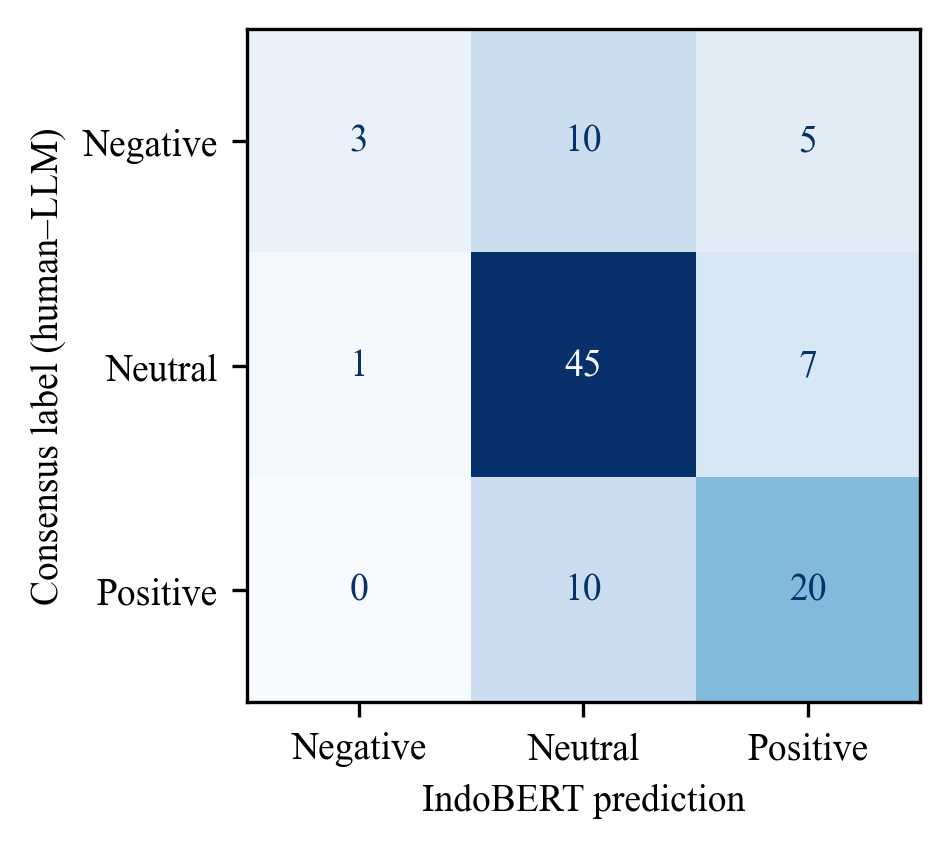

[[ 3 10  5]
 [ 1 45  7]
 [ 0 10 20]]


In [91]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

URUT = ['Negatif', 'Netral', 'Positif']
konsensus = (ann['Label_A'] == ann['Label_B']).values
cm = confusion_matrix(ann['Label_A'].values[konsensus], pred[konsensus], labels=URUT)

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 9})
fig, ax = plt.subplots(figsize=(3.4, 2.9), dpi=300)
ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Neutral', 'Positive']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_xlabel('IndoBERT prediction'); ax.set_ylabel('Consensus label (human–LLM)')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'confusion_matrix_konsensus.png', dpi=600, bbox_inches='tight')
plt.show()
print(cm)

In [ ]:
import shutil, os, datetime as dt, pandas as pd
    print(nama, '| backup bertanggal:',
          dt.datetime.fromtimestamp(os.path.getmtime(BACKUP / nama)).strftime('%Y-%m-%d %H:%M'))
    shutil.copy2(BACKUP / nama, DIR_PROCESSED / nama)

cek = pd.read_csv(DIR_PROCESSED / 'skor_sentimen_harian.csv')
print(cek.groupby('Emiten')['Sentiment_Mean'].mean().round(4).to_string())

skor_sentimen_harian.csv | backup bertanggal: 2026-11-05 12:55
sentiment_ready_for_merge.csv | backup bertanggal: 2026-11-05 12:55
Emiten
ADMR    0.3006
ADRO    0.2550
AKRA    0.2412
ITMG    0.2328
MEDC    0.2374
PGAS    0.1335
PTBA    0.1858


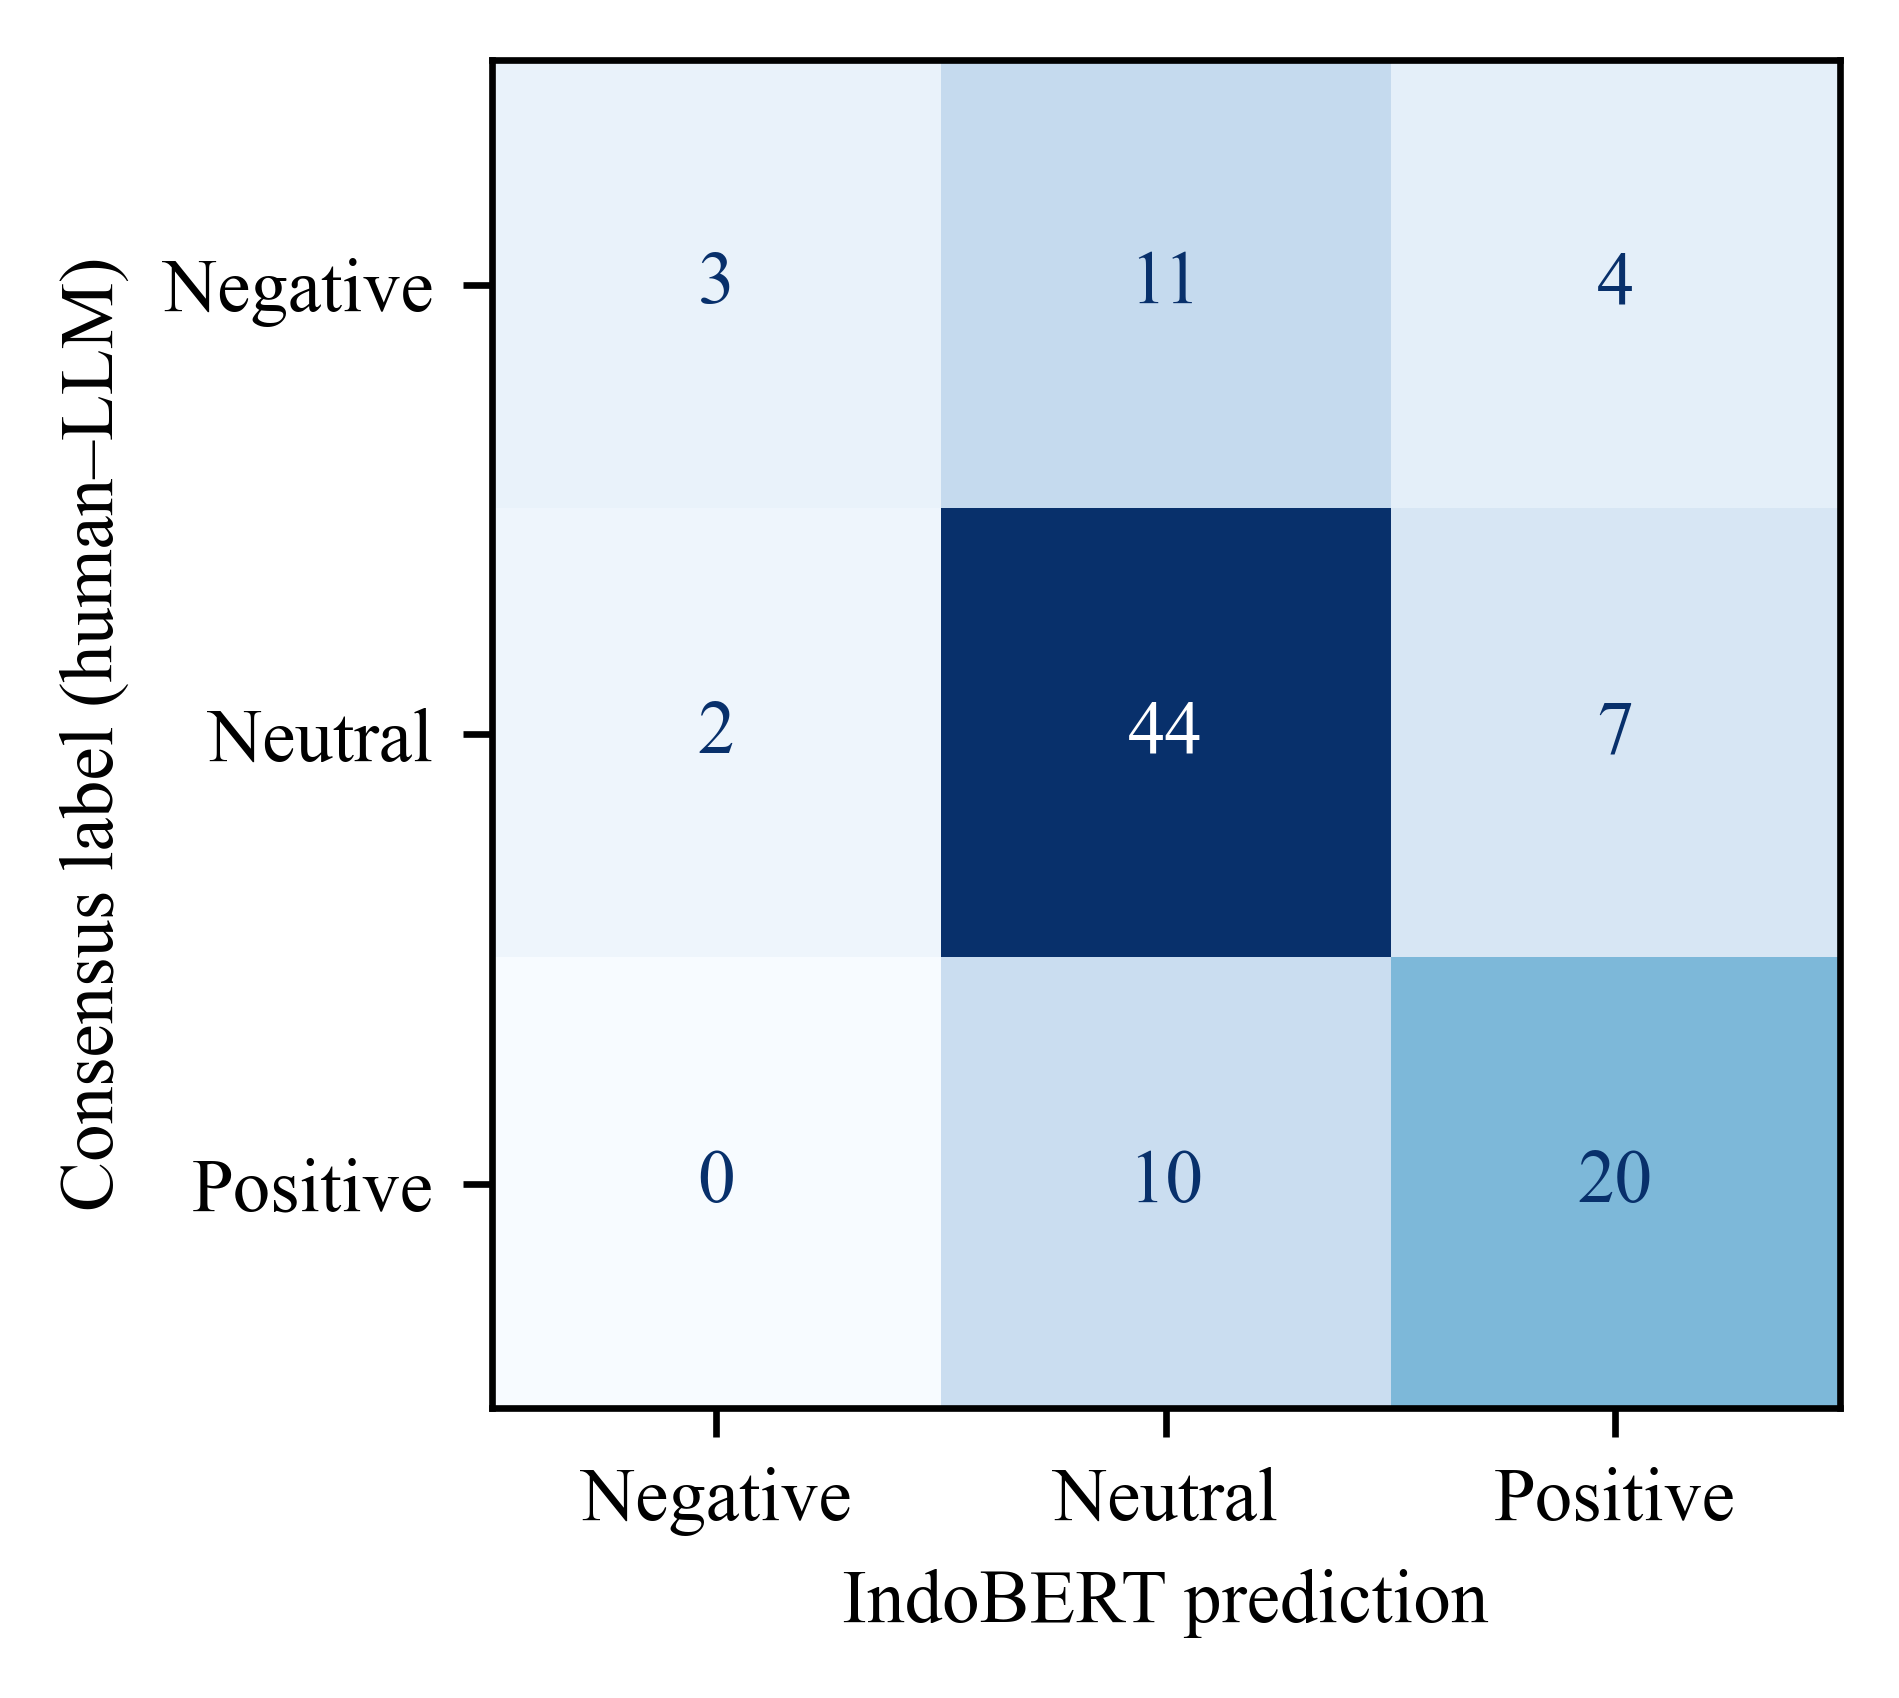

✅ Disimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\Fig2_confusion_matrix_konsensus_FINAL.png


In [94]:
# ════ FIG. 2 ARTIKEL — Confusion matrix konsensus (running asli 5 Nov) ════
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

cm = np.array([[3, 11, 4],     # konsensus Negatif
               [2, 44, 7],     # konsensus Netral
               [0, 10, 20]])   # konsensus Positif
assert cm.sum() == 101 and np.trace(cm) == 67      # akurasi 0,663

lab = ['Negative', 'Neutral', 'Positive']
with plt.rc_context({'font.family': 'Times New Roman', 'font.size': 9}):
    fig, ax = plt.subplots(figsize=(3.4, 2.9), dpi=600)
    ax.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else '#08306b')
    ax.set_xticks(range(3), lab); ax.set_yticks(range(3), lab)
    ax.set_xlabel('IndoBERT prediction')
    ax.set_ylabel('Consensus label (human–LLM)')
    plt.tight_layout()
    OUT = Path(r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian"
               r"\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing"
               r"\sentimen_indobert\output_sentimen 1\gambar\Fig2_confusion_matrix_konsensus_FINAL.png")
    plt.savefig(OUT, dpi=600)
    plt.show()
print('✅ Disimpan:', OUT)